# Feedforward Neural Networks: The Algebra and the Computing

<img alt="Cover of Feedforward Neural Networks" src="cover/Feedforward-Neural-Networks-Cover.png" width="360">

> **About this Python edition, version 1.0.0 (17 November 2026).** A port of the Wolfram notebook [`Feedforward-Neural-Networks.nb`](Feedforward-Neural-Networks.nb) (PDF: [`Feedforward-Neural-Networks.pdf`](Feedforward-Neural-Networks.pdf)) to Python 3.14 with NumPy, SciPy, SymPy, Matplotlib, NetworkX, ipywidgets and PyTorch. The text, the numbering of sections, equations, figures, tables and theorems, and the cell indices (c.N) are the same as in the Wolfram notebook. The networks are built and trained with NumPy alone; SymPy checks the derivatives, SciPy computes the LQR gains, and PyTorch takes the place of NetChain and NetTrain in section 10. The Manipulates and animations are shown as a single frame, which is what GitHub displays; in a running notebook their sliders work, and an animation starts only when its play button ▶ is pressed. The videos of the animations are in [`videos/`](videos), with a recording of the 3D Unity 6 version of the cart-pole and the learned pendulum ([in 4K on YouTube](https://youtu.be/lIUtEO9m79M)). Random numbers come from NumPy and PyTorch, so the values that depend on random weights differ slightly from the Wolfram run; the text gives the values of the Python run.

*A first network from ordinary functions: one neuron, a layer, a network, backpropagation and training, with AND, OR, XOR, Celsius to Fahrenheit, a stick balanced on a moving cart and a pendulum whose physics is learned*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="22">  
AI System Programming Group  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

A feedforward neural network is a chain of simple steps: multiply by a matrix, add a vector, apply an S-shaped function, and repeat. This notebook builds such a network from ordinary NumPy functions, one step at a time, and shows both the algebra and the computing behind each step. It opens with the smallest network that has every part, one input, one hidden neuron and one output, and carries out one learning step by hand: the forward pass, the loss, the backward pass by the chain rule, and the update, with every number written out and a slider that steps through the computation on a diagram. Then a single neuron computes the logical AND and OR; a layer of neurons is one matrix product, and processing many inputs at once turns it into a matrix-matrix product that runs about 60 times faster here than a loop. XOR cannot be computed by one neuron, which is proved, but a 2-2-1 network computes it, and a picture of its hidden layer shows why. The loss functions, the backpropagation equations and gradient descent are derived and programmed, and the gradients are checked against symbolic differentiation and finite differences. Four trainings follow, each shown with a slider or an animation. A network learns XOR from random weights, and a single neuron learns the rule F = 1.8 C + 32 from eight familiar temperatures, with its path over the loss landscape. Then two networks learn to keep a physical system moving. A 4-8-1 network learns to balance a stick on a cart by imitating a force-limited LQR controller: in the animation the untrained network drops the stick within a second, and after 100 epochs it holds it upright, even when the stick is hit. A 1-6-1 network learns the force law of a pendulum from 200 noisy measurements; run as a simulator, it keeps the pendulum swinging with the right period, 8.36 s against the true 8.35 s, where the textbook small-angle law gives 6.28 s, and it is proved that such a learned model conserves energy. Every network is also drawn as a diagram with its trained weights. Finally the same networks are built and trained with PyTorch (in the Wolfram notebook: NetChain and NetTrain), and the weights of a trained PyTorch network, run through our own code, reproduce its outputs to ${10}^{-7}$: the framework does exactly the algebra of this notebook.

**Keywords:** neuron; activation function; logistic sigmoid; matrix form; batch computation; XOR; hidden layer; linear separability; mean squared error; softmax; cross-entropy; backpropagation; chain rule; gradient descent; learning rate; Adam; cart-pole; inverted pendulum; LQR; imitation learning; learned dynamics; energy conservation; ipywidgets; PyTorch; NumPy; Python

Every code cell starts with a comment such as # c.9 giving its index, and the cells are meant to run in order from c.0. The interactive cells, c.0.4, c.13, c.14, c.17, c.20, c.21 and c.23, show one frame as an image; in a running notebook, moving their sliders or pressing ▶ draws the figure again under the controls. References of the form Figure M3 or Theorem M2 point to the notebook S Shape Functions Theory [1]. Numbers in square brackets refer to the list of references at the end.

## Index of equations, figures, tables, theorems and code cells

- A first look: Equations (0.1)–(0.5), Tables 0.1–0.3, Figures 0.1–0.2 (Figure 0.1 steps through the 13 steps with a slider), code cells c.0.1–c.0.5.
- Diagrams 1–5: the network of each example, drawn with its weights. Tables 1b, 5b, 7b, 9b, 11b and 12b: the same examples written as matrix products, with the actual numbers.
- Equations (1)–(3): one neuron and the logistic sigmoid; (4)–(5): a layer in matrix form and in batch form; (6)–(7): a network; (8)–(10): losses and softmax; (11)–(13): backpropagation; (14): gradient descent; (15): the Celsius–Fahrenheit neuron; (16)–(17): the cart-pole and its teacher; (18): a pendulum and its energy; (19): Adam.
- Figures 1–3: AND and OR, the XOR network, the hidden layer; Figure 4: training XOR (slider) and Figure 5 (animation); Figure 6: the walk over the loss (slider); Figure 7: learning to balance a stick (slider and animation); Figure 8: the trained network against pushes (animation); Figure 9: a learned pendulum (slider and animation).
- Tables 1–5: neurons, layers, timing, XOR; Table 6: backpropagation checked; Tables 7–9: training XOR and the temperature neuron; Tables 10–11: the cart-pole teacher and training; Table 12: the learned pendulum; Tables 13–14: the same networks in PyTorch; Table 15: the exported videos.
- Theorem 1: XOR is not linearly separable; Theorem 2: universal approximation; Theorem 3: backpropagation; Theorem 4: a learned force law conserves energy.
- Code cells c.0–c.26 (c.26 saves the animations as MP4 videos, Appendix B), with c.2b, c.12b, c.16b, c.19b and c.22b for the diagrams.

## 0. Settings

Font sizes and widths for every figure and table, so that the notebook also prints well on A4 paper.

In [1]:
# c.0
import re
import time
import shutil
import pathlib

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
from scipy.special import expit
from scipy.optimize import differential_evolution
from scipy.linalg import solve_continuous_are
import ipywidgets as widgets
from IPython.display import display, HTML

figFont = 14      # font size in figures and diagrams
tabFont = 10      # font size in tables
wFull = 440 / 72  # full figure width in inches (440 pt); A4 text width is ~487 pt
wHalf = 215 / 72  # width of each panel in a two-column figure (215 pt)
plt.rcParams.update({
    "font.size": figFont, "axes.titlesize": figFont, "axes.labelsize": figFont,
    "legend.fontsize": figFont, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False})
red, blue = (0.85, 0.2, 0.1), (0.1, 0.35, 0.85)
orange = (0.9, 0.45, 0.1)

def logistic_sigmoid(t):
    """LogisticSigmoid: 1/(1 + e^(-t)), without overflow warnings."""
    return expit(t)

def table(rows, label):
    """A framed table with a grey header row and a bold label on top."""
    cell = f"border:1px solid #999;padding:3px 8px;text-align:left;font-size:{tabFont}pt;vertical-align:middle"
    html = [f"<p style='font-weight:bold;font-size:{tabFont + 1}pt;margin-bottom:2px'>{label}</p>",
            "<table style='border-collapse:collapse'>"]
    for i, row in enumerate(rows):
        bg = "background:#ebebeb;" if i == 0 else ""
        html.append("<tr>" + "".join(f"<td style='{bg}{cell}'>{v}</td>" for v in row) + "</tr>")
    display(HTML("".join(html) + "</table>"))

def nform(v, d=4):
    """NumberForm[v, d]: d significant digits."""
    if isinstance(v, (bool, np.bool_)):
        return str(bool(v))
    if isinstance(v, (list, tuple, np.ndarray)):
        return "(" + ", ".join(nform(x, d) for x in np.ravel(v)) + ")"
    return f"{float(v):.{d}g}"

def sci(x):
    """ScientificForm[x, 2]: 2 significant digits, as m × 10^e."""
    m, e = f"{float(x):.1e}".split("e")
    return f"{m} × 10<sup>{int(e)}</sup>"

# matrices and column vectors as they are printed in the matrix-form tables:
# 3 significant digits, between brackets
def mat(m):
    m = np.atleast_2d(np.asarray(m, dtype=float))
    rows = "".join("<tr>" + "".join(f"<td style='border:none;padding:0 4px;text-align:right'>{x:.3g}</td>"
                                     for x in r) + "</tr>" for r in m)
    return ("<table style='display:inline-table;vertical-align:middle;border-collapse:separate;"
            "border-left:1.5px solid black;border-right:1.5px solid black;border-radius:6px;"
            f"margin:0 2px;font-size:{tabFont}pt'>{rows}</table>")

def col(v):
    return mat(np.reshape(np.asarray(v, dtype=float), (-1, 1)))

def row(*parts):
    return "".join(str(p) for p in parts)

def mtable(rows, label):
    """A matrix-form table: the label of each step printed above its formula."""
    table([["step and matrix form"]] +
          [[f"<i>{what}</i><br><div style='margin-top:6px'>{formula}</div>"] for what, formula in rows],
          label)

def fm(s):
    """'w_A' -> w with subscript A."""
    return re.sub(r"(\w)_(\w)", r"\1<sub>\2</sub>", s)

def fm_tex(s):
    """'w_A' -> w with subscript A, for Matplotlib text."""
    return re.sub(r"(\w)_(\w)", r"$\1_{\2}$", s)

# a diagram of any network: layer sizes, the weights (or None), labels for the
# inputs and outputs, and the symbol drawn in the output neurons. Red lines are
# positive weights, blue negative, and the thickness shows the size of the weight
def netDiagram(ax, sizes, net, inL, outL, outSym, title=""):
    L = len(sizes)
    pos = lambda l, i: (2.4 * (l - 1), (sizes[l - 1] + 1) / 2 - i)  # l, i from 1
    wmax = 1 if net is None else max(1e-9, max(np.abs(W).max() for W, b in net))
    few = sum(a * b for a, b in zip(sizes[:-1], sizes[1:])) <= 6 and net is not None
    for l in range(1, L):
        for i in range(1, sizes[l - 1] + 1):
            for j in range(1, sizes[l] + 1):
                w = 1 if net is None else net[l - 1][0][j - 1, i - 1]
                p, q = np.array(pos(l, i)), np.array(pos(l + 1, j))
                c = (0.55,) * 3 if net is None else (red if w > 0 else blue)
                lw = 1.2 if net is None else 0.5 + 4 * abs(w) / wmax
                ax.plot(*zip(p, q), color=c, lw=lw, zorder=1)
                if few:
                    ax.text(*(0.55 * p + 0.45 * q), f"{w:.3g}", fontsize=figFont - 4,
                            ha="center", va="center", zorder=3,
                            bbox=dict(fc="white", ec="none", pad=0.5))
    for l in range(1, L + 1):
        for i in range(1, sizes[l - 1] + 1):
            p = pos(l, i)
            if l == 1:
                ax.add_patch(plt.Rectangle((p[0] - 0.22, p[1] - 0.22), 0.44, 0.44,
                                           fc="white", ec="black", zorder=4))
                ax.text(p[0] - 0.45, p[1], inL[i - 1], ha="right", va="center", fontsize=figFont - 2)
            else:
                ax.add_patch(plt.Circle(p, 0.3, fc="white", ec="black", zorder=4))
                ax.text(*p, outSym if l == L else "σ", ha="center", va="center",
                        fontsize=figFont - 2, zorder=5)
                if l == L:
                    ax.text(p[0] + 0.5, p[1], outL[i - 1], ha="left", va="center", fontsize=figFont - 2)
                if few:
                    ax.text(p[0], p[1] - 0.5, f"b = {net[l - 2][1][i - 1]:.3g}", ha="center",
                            va="center", fontsize=figFont - 4, color="gray")
    xr = (-1.5, 2.4 * (L - 1) + 1.7)
    yr = (-(max(sizes) - 1) / 2 - (0.85 if few else 0.5), (max(sizes) - 1) / 2 + 0.5)
    ax.set(xlim=xr, ylim=yr, aspect="equal")
    ax.axis("off")
    if title:
        ax.set_title(title)
    return (xr[1] - xr[0]) * 42 / 72, (yr[1] - yr[0]) * 42 / 72   # size in inches, 42 pt per unit

def diagram(specs, label):
    """One or more network diagrams side by side, on one scale."""
    sizes = []
    fig, axs = plt.subplots(1, len(specs), squeeze=False)
    for ax, spec in zip(axs[0], specs):
        sizes.append(netDiagram(ax, *spec))
    fig.set_size_inches(sum(s[0] for s in sizes) + 0.3 * len(specs), max(s[1] for s in sizes) + 0.6)
    fig.suptitle(label, fontsize=figFont)
    plt.show()

# the interactive figures: view(fig, **values) draws one frame into fig. The
# frame for the values `still` is shown as an image (this is what GitHub shows);
# in a running notebook the controls redraw the figure under them. Animations
# use a Play button and start only when it is pressed
def slider(name, lo, hi, value=None, step=1):
    return widgets.IntSlider(value=lo if value is None else value, min=lo, max=hi, step=step,
                             description=name, continuous_update=True,
                             style={"description_width": "initial"},
                             layout=widgets.Layout(width="440px"))

def player(name, lo, hi, fps, step=1):
    s = slider(name, lo, hi, step=step)
    p = widgets.Play(value=lo, min=lo, max=hi, step=step, interval=int(1000 / fps))
    widgets.jslink((p, "value"), (s, "value"))
    return s, widgets.HBox([p, s])

def manipulate(view, figsize, controls, still, boxes=None):
    fig = plt.figure(figsize=figsize)
    view(fig, **still)
    plt.show()
    out = widgets.Output()
    def redraw(change=None):
        with out:
            out.clear_output(wait=True)
            f = plt.figure(figsize=figsize)
            view(f, **{k: c.value for k, c in controls.items()})
            plt.show()
    for c in controls.values():
        c.observe(redraw, names="value")
    display(widgets.VBox((boxes or list(controls.values())) + [out]))

## A first look: one learning step, by hand

Before any theory, here is the whole story on the smallest network that has every part: one input x, a hidden neuron A, an output neuron B and a target y. Each neuron multiplies its input by a weight, adds a bias and applies the S-shaped function σ(z) = 1/(1 + ${e}^{-z}$). We take x = 1 and want the output to be y = 1, and we start from weights chosen by hand: ${w}_{A}$ = ${w}_{B}$ = 0.5 and ${b}_{A}$ = ${b}_{B}$ = 0. Learning is three passes over this little chain, and every number is written out. Each weight here is a 1 × 1 matrix, so every matrix product of the later sections is an ordinary product in this example.

### Forward: compute the output

Go from left to right. Each neuron computes its weighted sum z and its output a; the output of A is the input of B. The loss L measures how far the answer ${a}_{B}$ is from the target:

$$
{z}_{A} = {w}_{A} \  x + {b}_{A} , {a}_{A} = \sigma ( {z}_{A} ) , {z}_{B} = {w}_{B} \  {a}_{A} + {b}_{B} , {a}_{B} = \sigma ( {z}_{B} ) \quad  \tag{0.1}
$$

$$
L = \frac{1}{2} {( {a}_{B} - y )}^{2} \quad  \tag{0.2}
$$

*Table 0.1. The forward pass: formula, the numbers put in, and the result.*

In [2]:
# c.0.1
# the smallest network with every part: input x, a hidden neuron A,
# an output neuron B, a target y. All numbers are chosen by hand
xIn, yT, rate = 1., 1., 1.            # input, target, learning rate
wA, bA, wB, bB = 0.5, 0., 0.5, 0.     # starting weights and biases

def nf(v):
    s = nform(v)
    return f"({s})" if v < 0 else s

# forward pass, Eqs. (0.1)-(0.2)
zA = wA * xIn + bA;  aA = logistic_sigmoid(zA)
zB = wB * aA + bB;   aB = logistic_sigmoid(zB)
lossAB = (aB - yT)**2 / 2
# each step: (formula, the numbers put in, value)
fwd = [
    ("z_A = w_A x + b_A", f"{nf(wA)} × {nf(xIn)} + {nf(bA)}", zA),
    ("a_A = σ(z_A)", f"1/(1 + e^-{nf(zA)})", aA),
    ("z_B = w_B a_A + b_B", f"{nf(wB)} × {nf(aA)} + {nf(bB)}", zB),
    ("a_B = σ(z_B)", f"1/(1 + e^-{nf(zB)})", aB),
    ("L = (a_B - y)²/2", f"({nf(aB)} - {nf(yT)})²/2", lossAB)]
table([["step", "formula", "numbers", "value"]] +
      [[k + 1, fm(f), n, nform(v)] for k, (f, n, v) in enumerate(fwd)], "Table 0.1. Forward pass")

step,formula,numbers,value
1,zA = wA x + bA,0.5 × 1 + 0,0.5
2,aA = σ(zA),1/(1 + e^-0.5),0.6225
3,zB = wB aA + bB,0.5 × 0.6225 + 0,0.3112
4,aB = σ(zB),1/(1 + e^-0.3112),0.5772
5,L = (aB - y)²/2,(0.5772 - 1)²/2,0.08939


### Backward: who is to blame?

Now go from right to left. To improve, each weight must know how much the loss changes when it changes: the derivative ∂L/∂w. The chain rule gives it as a product of the local derivatives along the path from the weight to the loss. The only derivative needed is that of σ, which is simply σ′(z) = a (1 - a) (Eq. (3) below). The number δ = ∂L/∂z of a neuron collects everything to its right, so it is computed once, at B first, and then passed back to A through the weight ${w}_{B}$:

$$
{\delta}_{B} = \frac{\partial L}{\partial {z}_{B}} = ( {a}_{B} - y ) \  {a}_{B} \  ( 1 - {a}_{B} ) , \frac{\partial L}{\partial {w}_{B}} = {\delta}_{B} \  {a}_{A} , \frac{\partial L}{\partial {b}_{B}} = {\delta}_{B} \quad  \tag{0.3}
$$

$$
\begin{gathered}{\delta}_{A} = \frac{\partial L}{\partial {z}_{A}} = {w}_{B} \  {\delta}_{B} \  {a}_{A} \  ( 1 - {a}_{A} ) , \frac{\partial L}{\partial {w}_{A}} = {\delta}_{A} \  x , \frac{\partial L}{\partial {b}_{A}} = {\delta}_{A} \\ \frac{\partial L}{\partial {w}_{A}} = \frac{\partial L}{\partial {a}_{B}} \cdot \frac{d {a}_{B}}{d {z}_{B}} \cdot \frac{\partial {z}_{B}}{\partial {a}_{A}} \cdot \frac{d {a}_{A}}{d {z}_{A}} \cdot \frac{\partial {z}_{A}}{\partial {w}_{A}} = ( {a}_{B} - y ) \cdot {\sigma}^{\prime} ( {z}_{B} ) \cdot {w}_{B} \cdot {\sigma}^{\prime} ( {z}_{A} ) \cdot x\end{gathered} \quad  \tag{0.4}
$$

The second line of Eq. (0.4) is the chain rule written out in full: five factors, one for each link from ${w}_{A}$ to L. Backpropagation is nothing more than computing these products from right to left, so that the common factors are computed only once.

*Table 0.2. The backward pass. All four derivatives are negative: increasing any weight or bias would bring ${a}_{B}$ closer to 1.*

In [3]:
# c.0.2
# backward pass, Eqs. (0.3)-(0.4): the chain rule from the loss back
# to every weight. σ′(z) = a (1 - a), Eq. (3)
dB = (aB - yT) * aB * (1 - aB)          # δ_B = ∂L/∂z_B
gwB = dB * aA;  gbB = dB
dA = wB * dB * aA * (1 - aA)            # δ_A = ∂L/∂z_A
gwA = dA * xIn; gbA = dA
bwd = [
    ("δ_B = (a_B - y) a_B (1 - a_B)", f"({nf(aB)} - {nf(yT)}) × {nf(aB)} × {nf(1 - aB)}", dB),
    ("∂L/∂w_B = δ_B a_A", f"{nf(dB)} × {nf(aA)}", gwB),
    ("∂L/∂b_B = δ_B", nf(dB), gbB),
    ("δ_A = w_B δ_B a_A (1 - a_A)", f"{nf(wB)} × {nf(dB)} × {nf(aA)} × {nf(1 - aA)}", dA),
    ("∂L/∂w_A = δ_A x", f"{nf(dA)} × {nf(xIn)}", gwA),
    ("∂L/∂b_A = δ_A", nf(dA), gbA)]
table([["step", "formula", "numbers", "value"]] +
      [[k + 6, fm(f), n, nform(v)] for k, (f, n, v) in enumerate(bwd)], "Table 0.2. Backward pass")

step,formula,numbers,value
6,δB = (aB - y) aB (1 - aB),(0.5772 - 1) × 0.5772 × 0.4228,-0.1032
7,∂L/∂wB = δB aA,(-0.1032) × 0.6225,-0.06423
8,∂L/∂bB = δB,(-0.1032),-0.1032
9,δA = wB δB aA (1 - aA),0.5 × (-0.1032) × 0.6225 × 0.3775,-0.01212
10,∂L/∂wA = δA x,(-0.01212) × 1,-0.01212
11,∂L/∂bA = δA,(-0.01212),-0.01212


### Update: take a small step downhill

Every weight and bias moves against its derivative, by the learning rate η = 1 times the derivative:

$$
{w}_{A} \leftarrow {w}_{A} - \eta \  \frac{\partial L}{\partial {w}_{A}} , {b}_{A} \leftarrow {b}_{A} - \eta \  \frac{\partial L}{\partial {b}_{A}} , {w}_{B} \leftarrow {w}_{B} - \eta \  \frac{\partial L}{\partial {w}_{B}} , {b}_{B} \leftarrow {b}_{B} - \eta \  \frac{\partial L}{\partial {b}_{B}} \quad  \tag{0.5}
$$

*Table 0.3. The update. The gradients of Table 0.2 agree with those computed by SymPy's symbolic derivative, and after one step the loss has dropped from 0.0894 to 0.0751.*

In [4]:
# c.0.3
# one gradient-descent step, Eq. (0.5), and two checks: the gradients
# against SymPy's symbolic derivative, and the loss before and after
newP = np.array([wA, bA, wB, bB]) - rate * np.array([gwA, gbA, gwB, gbB])
def lossOf(P):
    p, q, r, s = P
    return (logistic_sigmoid(r * logistic_sigmoid(p * xIn + q) + s) - yT)**2 / 2
p, q, r, s = sp.symbols("p q r s")
sig = lambda z: 1 / (1 + sp.exp(-z))
lossSym = (sig(r * sig(p * xIn + q) + s) - yT)**2 / 2
gradD = [float(sp.diff(lossSym, v).subs({p: wA, q: bA, r: wB, s: bB})) for v in (p, q, r, s)]
table([["parameter", "old", "gradient", "gradient by SymPy", "new"]] +
      [[fm(n), nform(o), nform(g), nform(gd), nform(nw)] for n, o, g, gd, nw in
       zip(["w_A", "b_A", "w_B", "b_B"], [wA, bA, wB, bB], [gwA, gbA, gwB, gbB], gradD, newP)] +
      [["loss L", nform(lossAB), "", "", nform(lossOf(newP))]], "Table 0.3. The update")

parameter,old,gradient,gradient by SymPy,new
wA,0.5,-0.01212,-0.01212,0.5121
bA,0,-0.01212,-0.01212,0.01212
wB,0.5,-0.06423,-0.06423,0.5642
bB,0,-0.1032,-0.1032,0.1032
loss L,0.08939,,,0.0751


*Figure 0.1. The 13 steps on the network, shown at step 13. Move the slider: forward results appear in blue above the neurons, backward results in red below, with the current step highlighted and written out in full under the diagram.*

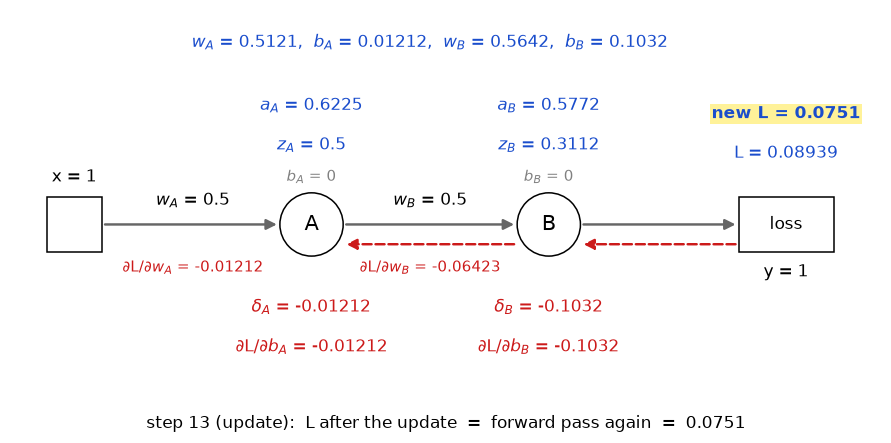

In [5]:
# c.0.4
# the computation step by step on the network: forward values appear
# in blue above the neurons, backward ones in red below
upd = ("w_A, b_A, w_B, b_B ← old - η × gradient", f"η = {nf(rate)}", newP)
again = ("L after the update", "forward pass again", lossOf(newP))
allSteps = fwd + bwd + [upd, again]
def phase(k):
    return "forward pass" if k <= 5 else "backward pass" if k <= 11 else "update"
# where each result is written on the diagram
spot = [(3, 1.0), (3, 1.5), (6, 1.0), (6, 1.5), (9, 0.9), (6, -1.05), (4.5, -0.55),
        (6, -1.55), (3, -1.05), (1.5, -0.55), (3, -1.55), (4.5, 2.3), (9, 1.4)]
short = ["z_A", "a_A", "z_B", "a_B", "L", "δ_B", "∂L/∂w_B", "∂L/∂b_B",
         "δ_A", "∂L/∂w_A", "∂L/∂b_A", "new weights", "new L"]
nl = lambda v: nform(v)                     # no brackets in labels

def tinyNet(ax, k):
    gray = (0.4,) * 3
    arrow = lambda p, q, **kw: ax.annotate("", q, p, arrowprops=dict(arrowstyle="-|>", lw=1.6, **kw))
    for p, q in [((0.35, 0), (2.6, 0)), ((3.4, 0), (5.6, 0)), ((6.4, 0), (8.4, 0))]:
        arrow(p, q, color=gray)
    if k >= 6:
        arrow((8.4, -0.25), (6.4, -0.25), color=(0.8, 0.1, 0.1), ls="--")
        if k >= 9:
            arrow((5.6, -0.25), (3.4, -0.25), color=(0.8, 0.1, 0.1), ls="--")
    ax.add_patch(plt.Rectangle((-0.35, -0.35), 0.7, 0.7, fc="white", ec="black"))
    ax.add_patch(plt.Circle((3, 0), 0.4, fc="white", ec="black"))
    ax.add_patch(plt.Circle((6, 0), 0.4, fc="white", ec="black"))
    ax.add_patch(plt.Rectangle((8.4, -0.35), 1.2, 0.7, fc="white", ec="black"))
    t = lambda x, y, s, size=figFont - 3, **kw: ax.text(x, y, s, ha="center", va="center",
                                                        fontsize=size, **kw)
    t(0, 0.6, f"x = {nf(xIn)}"); t(3, 0, "A", figFont); t(6, 0, "B", figFont)
    t(9, 0, "loss"); t(9, -0.6, f"y = {nf(yT)}")
    t(1.5, 0.3, f"$w_A$ = {nf(wA)}"); t(4.5, 0.3, f"$w_B$ = {nf(wB)}")
    t(3, 0.6, f"$b_A$ = {nf(bA)}", figFont - 4, color="gray")
    t(6, 0.6, f"$b_B$ = {nf(bB)}", figFont - 4, color="gray")
    for j in range(1, k + 1):
        st = allSteps[j - 1]
        c = (0.8, 0.1, 0.1) if 6 <= j <= 11 else (0.1, 0.3, 0.8)
        if j == 12:
            s = ",  ".join(f"{fm_tex(n)} = {nl(v)}" for n, v in zip(["w_A", "b_A", "w_B", "b_B"], st[2]))
        else:
            s = f"{fm_tex(short[j - 1])} = {nl(st[2])}"
        t(*spot[j - 1], s, figFont - 4 if j in (7, 10) else figFont - 3, color=c,
          fontweight="bold" if j == k else "normal",
          bbox=dict(fc=(1, 0.95, 0.6), ec="none", pad=1) if j == k else None)
    ax.set(xlim=(-0.8, 10.2), ylim=(-1.9, 2.7), aspect="equal")
    ax.axis("off")

# one view per step; the slider moves through them
def stepView(fig, k):
    fig.clf()
    ax = fig.add_axes([0, 0.18, 1, 0.82])
    tinyNet(ax, k)
    st = allSteps[k - 1]
    val = nform(st[2]) if k == 12 else nl(st[2])
    fig.text(0.5, 0.06, f"step {k} ({phase(k)}):  {fm_tex(st[0])}  =  {st[1]}  =  {val}",
             ha="center", fontsize=figFont - 3)

kStep = slider("step", 1, len(allSteps))
manipulate(stepView, (wFull * 1.3, wFull * 0.66), {"k": kStep}, {"k": len(allSteps)})

▶ **Video:** [Tiny-network-13-steps.mp4](videos/Tiny-network-13-steps.mp4), the 13 steps of Figure 0.1.

Repeating the three passes is training. After 100 steps the output is above 0.93 and still climbing towards 1. The rest of this notebook does exactly this, with more neurons per layer, matrices instead of single numbers, and many examples at once.

*Figure 0.2. 100 repetitions of forward, backward and update.*

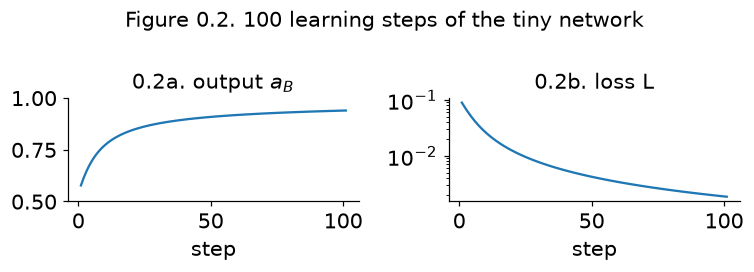

In [6]:
# c.0.5
# repeat the same step: forward, backward, update. The output a_B
# climbs towards the target y = 1 and the loss falls
# one learning step for the parameters (w_A, b_A, w_B, b_B)
def gdStep(P):
    p, q, r, s = P
    a1 = logistic_sigmoid(p * xIn + q); a2 = logistic_sigmoid(r * a1 + s)
    d2 = (a2 - yT) * a2 * (1 - a2); d1 = r * d2 * a1 * (1 - a1)
    return P - rate * np.array([d1 * xIn, d1, d2 * a1, d2])
# 100 steps from the hand-picked start
runP = [np.array([wA, bA, wB, bB])]
for _ in range(100):
    runP.append(gdStep(runP[-1]))
# the output a_B after every step
outP = [logistic_sigmoid(P[2] * logistic_sigmoid(P[0] * xIn + P[1]) + P[3]) for P in runP]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(2 * wHalf + 1, wHalf * 0.85))
a1.plot(range(1, 102), outP); a1.set(ylim=(0.5, 1), xlabel="step", title="0.2a. output $a_B$")
a2.semilogy(range(1, 102), [lossOf(P) for P in runP]); a2.set(xlabel="step", title="0.2b. loss L")
fig.suptitle("Figure 0.2. 100 learning steps of the tiny network", fontsize=figFont)
fig.tight_layout()
plt.show()

## 1. One neuron

A neuron takes n numbers ${x}_{1}$, …, ${x}_{n}$, multiplies each by a weight ${w}_{i}$, adds them and adds a bias b. The result z is then passed through an activation function, here the logistic sigmoid σ:

$$
\begin{gathered}z = w \cdot x + b = {\sum}_{i = 1}^{n} {w}_{i} \  {x}_{i} + b \\ w \cdot x = {w}^{T} x = \begin{pmatrix}{w}_{1} & {w}_{2} & \cdots & {w}_{n}\end{pmatrix} \begin{pmatrix}{x}_{1} \\ {x}_{2} \\ \vdots \\ {x}_{n}\end{pmatrix} = {w}_{1} {x}_{1} + {w}_{2} {x}_{2} + \cdots + {w}_{n} {x}_{n}\end{gathered} \quad  \tag{1}
$$

$$
a = \sigma ( z ) = \frac{1}{1 + {e}^{- z}} \quad  \tag{2}
$$

The dot product w·x is the matrix product of the row of weights with the column of inputs, as the second line of Eq. (1) shows: a 1 × n matrix times an n × 1 matrix gives a 1 × 1 matrix, the number z. Every computation in this notebook is built from this one product.

σ squeezes any real number into (0, 1): very negative z gives almost 0, very positive z almost 1, and z = 0 gives exactly 1/2. Its derivative has a convenient form, which backpropagation will use in every layer:

$$
{\sigma}^{\prime} ( z ) = \sigma ( z ) \  ( 1 - \sigma ( z ) ) \quad  \tag{3}
$$

With two inputs that are 0 or 1, one neuron can compute logic. The weights 20, 20 and the bias -30 give z > 0 only when both inputs are 1: that is AND. With bias -10, z > 0 as soon as one input is 1: that is OR. The large weights make σ nearly a step.

*Table 1. AND and OR computed by one neuron: z and σ(z) for all four inputs.*

In [7]:
# c.1
# one neuron, Eqs. (1)-(2): weighted sum plus bias, then σ
def neuron(w, b):
    return lambda x: logistic_sigmoid(np.dot(w, x) + b)
# hand-picked weights: AND fires only when both inputs are 1,
# OR fires when at least one is
andN = neuron([20, 20], -30)
orN = neuron([20, 20], -10)
# the four inputs (0,0), (0,1), (1,0), (1,1)
inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
# z = w·x + b and the output σ(z) for every input
table([["x<sub>1</sub>", "x<sub>2</sub>", "z (AND)", "σ(z) AND", "z (OR)", "σ(z) OR"]] +
      [[x[0], x[1], 20 * x[0] + 20 * x[1] - 30, nform(andN(x), 3),
        20 * x[0] + 20 * x[1] - 10, nform(orN(x), 3)] for x in inputs], "Table 1")

x1,x2,z (AND),σ(z) AND,z (OR),σ(z) OR
0,0,-30,9.36e-14,-10,4.54e-05
0,1,-10,4.54e-05,10,1
1,0,-10,4.54e-05,10,1
1,1,10,1,30,1


*Table 1b. The AND neuron written as matrices: the row (20 20) times the input column, plus the bias, for each of the four inputs.*

In [8]:
# c.1b
# the AND neuron in matrix form: w is a 1×2 row, x a 2×1 column, and
# w·x is the row times the column
wAND = np.array([[20, 20]]); bAND = np.array([-30])
table([["z = w x + b", "σ(z)"]] +
      [[row(mat(wAND), " ", col(x), " + ", col(bAND), " = ", col(wAND @ x + bAND)),
        nform(logistic_sigmoid((wAND @ x + bAND)[0]), 3)] for x in inputs],
      "Table 1b. The AND neuron as a matrix product")

Geometrically, σ(w·x + b) > 1/2 exactly where w·x + b > 0, which is one side of the line w·x + b = 0. A neuron therefore splits the plane into two half-planes, with a soft transition of width about 1/|w| across the line.

*Figure 1. The output of the AND and OR neurons over the plane, from blue (0) to red (1). The dashed line is w·x + b = 0; white dots are inputs whose answer is 1.*

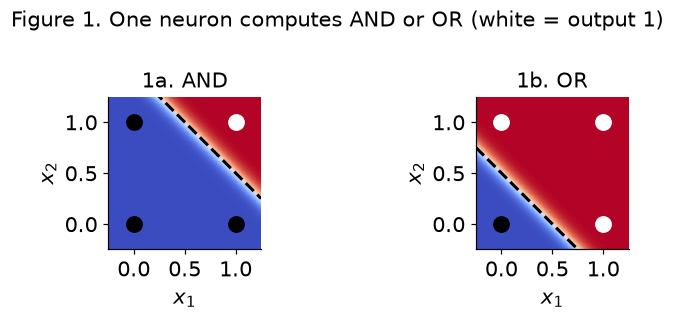

In [9]:
# c.2
# each neuron is a soft half-plane: σ(w·x + b) > 1/2 exactly where
# w·x + b > 0. The dashed line is the boundary w·x + b = 0
# nfun: the neuron, b: its bias, truth: the logic rule for the dots
g2 = np.linspace(-0.25, 1.25, 121)
X1, X2 = np.meshgrid(g2, g2)
def gatePlot(ax, nfun, b, lbl, truth):
    Z = nfun(np.stack([X1, X2]).reshape(2, -1)).reshape(X1.shape)
    ax.imshow(Z, origin="lower", extent=(-0.25, 1.25, -0.25, 1.25), cmap="coolwarm",
              vmin=0, vmax=1)
    # the line 20 x1 + 20 x2 + b = 0, solved for x2
    ax.plot([-0.25, 1.25], [(-b - 20 * -0.25) / 20, (-b - 20 * 1.25) / 20], "k--", lw=2)
    for x in inputs:
        ax.plot(*x, "o", ms=10, color="white" if truth(x) else "black")
    ax.set(xlim=(-0.25, 1.25), ylim=(-0.25, 1.25), xticks=[0, 0.5, 1], yticks=[0, 0.5, 1],
           xlabel="$x_1$", ylabel="$x_2$", title=lbl)
fig, axs = plt.subplots(1, 2, figsize=(2 * wHalf + 1, wHalf))
gatePlot(axs[0], neuron([20, 20], -30), -30, "1a. AND", lambda x: x[0] & x[1])
gatePlot(axs[1], neuron([20, 20], -10), -10, "1b. OR", lambda x: x[0] | x[1])
fig.suptitle("Figure 1. One neuron computes AND or OR (white = output 1)", fontsize=figFont)
fig.tight_layout()
plt.show()

The same two neurons drawn as networks, the way every network in this notebook is drawn: squares are inputs, circles are neurons with their activation written inside (σ, or Σ for a plain weighted sum with no σ). Red lines are positive weights, blue lines negative ones, and a thicker line is a larger weight; on small networks the weights and biases are written out.

*Diagram 1. The AND and OR neurons of Table 1.*

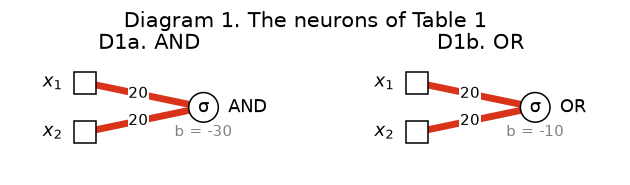

In [10]:
# c.2b
# the AND and OR neurons as diagrams: squares are inputs, the circle
# is the neuron; numbers on the lines are weights, b is the bias
diagram([([2, 1], [(np.array([[20, 20]]), np.array([-30]))], ["$x_1$", "$x_2$"], ["AND"], "σ", "D1a. AND"),
         ([2, 1], [(np.array([[20, 20]]), np.array([-10]))], ["$x_1$", "$x_2$"], ["OR"], "σ", "D1b. OR")],
        "Diagram 1. The neurons of Table 1")

## 2. A layer is a matrix product

Put m neurons side by side, all reading the same input x. Their weight vectors become the rows of an m × n matrix W, their biases a vector b, and the whole layer is one matrix-vector product followed by σ applied to each component:

$$
\begin{gathered}\begin{pmatrix}{z}_{1} \\ {z}_{2} \\ \vdots \\ {z}_{m}\end{pmatrix} = \begin{pmatrix}{w}_{11} & {w}_{12} & \cdots & {w}_{1 n} \\ {w}_{21} & {w}_{22} & \cdots & {w}_{2 n} \\ \vdots & \vdots & \ddots & \vdots \\ {w}_{m 1} & {w}_{m 2} & \cdots & {w}_{m n}\end{pmatrix} \begin{pmatrix}{x}_{1} \\ {x}_{2} \\ \vdots \\ {x}_{n}\end{pmatrix} + \begin{pmatrix}{b}_{1} \\ {b}_{2} \\ \vdots \\ {b}_{m}\end{pmatrix} \\ a = \sigma ( z ) = \begin{pmatrix}\sigma ( {z}_{1} ) \\ \vdots \\ \sigma ( {z}_{m} )\end{pmatrix} , W \in {\mathbb{R}}^{m \times n}\end{gathered} \quad  \tag{4}
$$

Row i of W holds the weights of neuron i; column j holds the weights that input ${x}_{j}$ sends to every neuron. Nothing more is going on inside a layer than this product.

*Table 2. A layer of 3 neurons on 2 inputs: the symbolic product W x + b, and one numeric example.*

In [11]:
# c.3
# a layer of m neurons is one matrix product, Eq. (4): z = W x + b,
# then σ applied to every component
def layer(W, b):
    return lambda x: logistic_sigmoid(W @ x + b)
# symbols: w_ij is the weight from input j to neuron i
Wsym = sp.Matrix(3, 2, lambda i, j: sp.Symbol(f"w_{i + 1}{j + 1}"))
bsym = sp.Matrix(3, 1, lambda i, j: sp.Symbol(f"b_{i + 1}"))
xsym = sp.Matrix(2, 1, lambda i, j: sp.Symbol(f"x_{i + 1}"))
symText = lambda e: re.sub(r"(\w)_(\d+)", r"\1<sub>\2</sub>", str(e).replace("*", " "))
symCol = lambda m: ("<table style='display:inline-table;border-left:1.5px solid black;"
                    "border-right:1.5px solid black;border-radius:6px'>" +
                    "".join(f"<tr><td style='border:none;padding:0 4px'>{symText(e)}</td></tr>" for e in m) +
                    "</table>")
# a numeric example: 2 inputs, 3 neurons
W1 = np.array([[1., -2.], [0.5, 0.5], [-1., 3.]]); b1 = np.array([0., -0.5, 1.])
x0 = np.array([0.8, 0.3])
# the product W x + b, symbolic and with numbers
table([["quantity", "value"],
       ["W x + b, symbolic", symCol(Wsym * xsym + bsym)],
       ["W, numeric", mat(W1)], ["b", col(b1)], ["x", col(x0)],
       ["z = W x + b", col(W1 @ x0 + b1)],
       ["a = σ(z)", col(np.round(layer(W1, b1)(x0), 4))]], "Table 2")

### The computing: many inputs at once

In practice a network is applied to many inputs, and a computer is much faster at one large matrix product than at many small ones. Put M inputs as the rows of an M × n matrix X. Then all M results come from one product, the bias is added to every row, and σ is applied entrywise:

$$
Z = X \  {W}^{T} + 1 \  {b}^{T} , A = \sigma ( Z ) , X \in {\mathbb{R}}^{M \times n} , A \in {\mathbb{R}}^{M \times m} \quad  \tag{5}
$$

This row convention, one sample per row, is the one used in the code from now on; it is why the code writes X ${W}^{T}$ where the equations write W x.

*Table 3. 100000 inputs through the same layer, one at a time and as one matrix.*

In [12]:
# c.4
# the computing: M inputs at once. Put them as the rows of a matrix
# X (M × n); the whole layer is then one matrix product, Eq. (5)
def layerBatch(W, b):
    return lambda X: logistic_sigmoid(X @ W.T + b)   # b is added to every row
rng = np.random.default_rng(1)
# 100000 random inputs, one per row
Xbig = rng.uniform(0, 1, (100000, 2))
# time both: a loop over the rows, and one matrix product
t = time.perf_counter(); r1 = np.array([layer(W1, b1)(x) for x in Xbig]); tLoop = time.perf_counter() - t
t = time.perf_counter(); r2 = layerBatch(W1, b1)(Xbig); tBatch = time.perf_counter() - t
table([["method", "time (s)", "same result?"],
       ["one input at a time (loop)", nform(tLoop, 3), ""],
       ["all inputs as one matrix", nform(tBatch, 3), np.abs(r1 - r2).max() < 1e-12],
       ["speed-up", nform(tLoop / tBatch, 3), ""]], "Table 3")

method,time (s),same result?
one input at a time (loop),0.221,
all inputs as one matrix,0.00301,True
speed-up,73.5,


## 3. Stacking layers: the network

A network feeds the output of one layer into the next. Write the input as ${a}^{0}$ and number the layers l = 1, …, L; layer l has its own ${W}^{l}$ and ${b}^{l}$ (superscripts number layers here, they are not powers):

$$
\begin{gathered}{a}^{0} = x , {z}^{l} = {W}^{l} \  {a}^{l - 1} + {b}^{l} , {a}^{l} = \sigma ( {z}^{l} ) , l = 1 , \ldots , L \\ f ( x ) = {a}^{L} = \sigma ( {W}^{L} \  \sigma ( {W}^{L - 1} \  \ldots \sigma ( {W}^{1} x + {b}^{1} ) \ldots + {b}^{L - 1} ) + {b}^{L} )\end{gathered} \quad  \tag{6}
$$

The second line writes the whole network as one function: a composition of affine maps and σ. Why is more than one layer needed? The classic answer is XOR [2].

**Theorem 1 (XOR is not linearly separable).** There are no w = (${w}_{1}$, ${w}_{2}$) and b with w·x + b > 0 for x = (0,1) and (1,0) and w·x + b ≤ 0 for x = (0,0) and (1,1). Hence no single neuron computes XOR.

**Proof.** Adding the two strict inequalities ${w}_{2}$ + b > 0 and ${w}_{1}$ + b > 0 gives ${w}_{1}$ + ${w}_{2}$ + 2b > 0. Adding the other two, b ≤ 0 and ${w}_{1}$ + ${w}_{2}$ + b ≤ 0, gives ${w}_{1}$ + ${w}_{2}$ + 2b ≤ 0, a contradiction. ∎

*Table 4. The best a single neuron can do on XOR, by minimizing its squared error (SciPy's differential_evolution, the method of Wolfram's NMinimize there): a total squared error of 1, no better than answering 0.5 everywhere. The error has several minima of the same height: this run finds a neuron that gets one input right and answers 0 elsewhere, the Wolfram run found the neuron that answers 0.5 everywhere.*

In [13]:
# c.5
# XOR: 1 when exactly one input is 1. Try the best single neuron:
# minimize the squared error over its three parameters
xorY = inputs[:, 0] ^ inputs[:, 1]
def singleErr(P):
    return np.sum((logistic_sigmoid(inputs @ P[:2] + P[2]) - xorY)**2)
single = differential_evolution(singleErr, [(-30, 30)] * 3, seed=1, tol=1e-12)
# the outputs of the best neuron found, beside the answer 0.5 everywhere
bestOut = logistic_sigmoid(inputs @ single.x[:2] + single.x[2])
table([["x<sub>1</sub>", "x<sub>2</sub>", "XOR", "best single neuron", "0.5 everywhere"]] +
      [[inputs[k, 0], inputs[k, 1], xorY[k], nform(bestOut[k], 3), 0.5] for k in range(4)] +
      [["squared error", "", "", nform(singleErr(single.x), 3), nform(np.sum((0.5 - xorY)**2), 3)]],
      "Table 4")

x1,x2,XOR,best single neuron,0.5 everywhere
0,0,0,3.42e-07,0.5
0,1,1,1,0.5
1,0,1,3.91e-20,0.5
1,1,0,2.8e-07,0.5
squared error,,,1,1


Two layers solve it. XOR is true when OR is true and NAND (not both) is true, and each of these is one neuron. So a hidden layer with an OR neuron and a NAND neuron, followed by an AND neuron, computes

$$
\begin{gathered}y = \sigma ( 20 \  \sigma ( 20 {x}_{1} + 20 {x}_{2} - 10 ) + 20 \  \sigma ( - 20 {x}_{1} - 20 {x}_{2} + 30 ) - 30 ) \\ y = \sigma ( \begin{pmatrix}20 & 20\end{pmatrix} \  \sigma ( \begin{pmatrix}20 & 20 \\ - 20 & - 20\end{pmatrix} \  \begin{pmatrix}{x}_{1} \\ {x}_{2}\end{pmatrix} + \begin{pmatrix}- 10 \\ 30\end{pmatrix} ) - 30 )\end{gathered} \quad  \tag{7}
$$

*Table 5. The forward pass of the XOR network for the four inputs, with every intermediate value.*

In [14]:
# c.6
# a 2-2-1 network that computes XOR, Eq. (7): hidden neuron 1 is OR,
# hidden neuron 2 is NAND, the output neuron is AND of the two
Wh = np.array([[20., 20.], [-20., -20.]]); bh = np.array([-10., 30.])
Wo = np.array([[20., 20.]]); bo = np.array([-30.])
# the network: the hidden layer first, then the output layer
xorNet = lambda x: layer(Wo, bo)(layer(Wh, bh)(x))
# every intermediate value of the forward pass
rows = [["x", "z hidden", "h = σ(z)", "z out", "output", "XOR"]]
for x in inputs:
    zh = Wh @ x + bh; hv = logistic_sigmoid(zh)
    rows.append([tuple(int(v) for v in x), tuple(int(v) for v in zh), nform(hv, 3),
                 nform((Wo @ hv + bo)[0], 3), nform(xorNet(x)[0], 3), x[0] ^ x[1]])
table(rows, "Table 5")

x,z hidden,h = σ(z),z out,output,XOR
"(0, 0)","(-10, 30)","(4.54e-05, 1)",-10,4.54e-05,0
"(0, 1)","(10, 10)","(1, 1)",10,1,1
"(1, 0)","(10, 10)","(1, 1)",10,1,1
"(1, 1)","(30, -10)","(1, 4.54e-05)",-10,4.54e-05,0


The same network in matrix form. The hidden layer has 2 neurons reading 2 inputs, so its W is 2 × 2 (row i holds the weights of neuron i) and b has 2 entries; the output layer has 1 neuron reading 2 hidden values, so its W is 1 × 2. The second line of Eq. (7) writes the network with these matrices. With the four inputs as the rows of X, Eq. (5) computes all of them with one product per layer.

*Table 5b. The XOR network as matrix products: first for the input (1, 0), then for all four inputs at once. Note the shapes: X is 4 × 2, Wᵀ is 2 × 2, and Z is 4 × 2, one row per input and one column per hidden neuron.*

In [15]:
# c.6b
# the XOR network in matrices: one input, then all four at once.
# Hidden layer: W is 2×2 (2 neurons × 2 inputs), b is 2×1. Output
# layer: W is 1×2 (1 neuron × 2 hidden values), b is 1×1
xEx = np.array([1, 0])
zH = Wh @ xEx + bh; hH = logistic_sigmoid(zH)
zO = Wo @ hH + bo
# batch, Eq. (5): the 4 inputs are the rows of X (4×2)
ZH = inputs @ Wh.T + np.tile(bh, (4, 1))
HH = logistic_sigmoid(ZH)
ZO = HH @ Wo.T + np.tile(bo, (4, 1))
mtable([
    ("hidden layer, x = (1, 0):  z = W x + b,  h = σ(z)",
     row(mat(Wh), " ", col(xEx), " + ", col(bh), " = ", col(zH), ",    σ", col(zH), " = ", col(hH))),
    ("output layer:  z = W h + b,  y = σ(z)",
     row(mat(Wo), " ", col(hH), " + ", col(bo), " = ", col(zO), ",    σ", col(zO), " = ",
         col(logistic_sigmoid(zO)))),
    ("hidden layer, all 4 inputs as rows:  Z = X Wᵀ + B",
     row(mat(inputs), " ", mat(Wh.T), " + ", mat(np.tile(bh, (4, 1))), " = ", mat(ZH))),
    ("H = σ(Z), entry by entry", row("σ", mat(ZH), " = ", mat(HH))),
    ("output layer, all 4 inputs:  Z = H Wᵀ + B,  Y = σ(Z)",
     row(mat(HH), " ", mat(Wo.T), " + ", mat(np.tile(bo, (4, 1))), " = ", mat(ZO), ",    σ", mat(ZO),
         " = ", mat(logistic_sigmoid(ZO))))],
    "Table 5b. The XOR network as matrix products")

*Figure 2. The XOR network as a graph, in the style of Figure M3. Red: weights on the arrows; blue: biases of the neurons.*

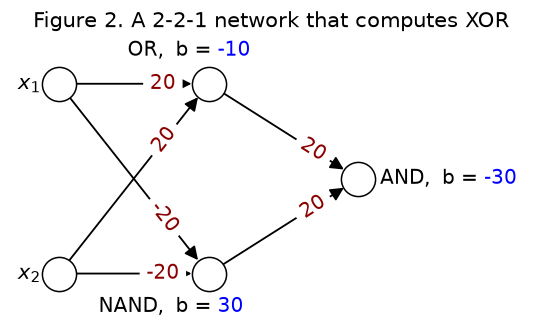

In [16]:
# c.7
# the XOR network drawn like Figure M3 of S Shape Functions Theory;
# red labels are the weights, blue the biases
xorEdges = [("x1", "h1"), ("x2", "h1"), ("x1", "h2"), ("x2", "h2"), ("h1", "y"), ("h2", "y")]
G = nx.DiGraph(xorEdges)
xy = {"x1": (0, 1), "x2": (0, -1), "h1": (2.5, 1), "h2": (2.5, -1), "y": (5, 0)}
fig, ax = plt.subplots(figsize=(wFull, 0.55 * wFull))
nx.draw_networkx_nodes(G, xy, ax=ax, node_size=500, node_color="white", edgecolors="black")
nx.draw_networkx_edges(G, xy, ax=ax, node_size=500, arrowsize=18, width=1.2)
nx.draw_networkx_edge_labels(G, xy, ax=ax, label_pos=0.72, font_size=figFont - 1, font_color="darkred",
                             edge_labels=dict(zip(xorEdges, [20, 20, -20, -20, 20, 20])))
ax.text(-0.3, 1, "$x_1$", ha="right", va="center"); ax.text(-0.3, -1, "$x_2$", ha="right", va="center")
for name, (x, y), dx, dy, b in [("OR", xy["h1"], 0.15, 0.35, -10), ("NAND", xy["h2"], 0.15, -0.35, 30),
                                ("AND", xy["y"], 2.1, 0, -30)]:
    ax.text(x + dx, y + dy, f"{name},  b = ", ha="right", va="center", fontsize=figFont - 1)
    ax.text(x + dx, y + dy, f"{b}", ha="left", va="center", fontsize=figFont - 1, color="blue")
ax.set(xlim=(-0.8, 7.9), ylim=(-1.5, 1.5))
ax.axis("off")
ax.set_title("Figure 2. A 2-2-1 network that computes XOR")
plt.show()

The hidden layer does not answer the question; it changes the question. It moves the four inputs to new points h = σ(W x + b). The two inputs whose answer is 1 both land on (1, 1), and the other two on (0, 1) and (1, 0). In these new coordinates one straight line separates the classes, and a single output neuron can finish the job. This is what hidden layers do in general: they transform the data until a simple rule works.

*Figure 3. Left: the XOR inputs, which no line separates. Right: the same points after the hidden layer, separated by the dashed line ${h}_{1}$ + ${h}_{2}$ = 1.5.*

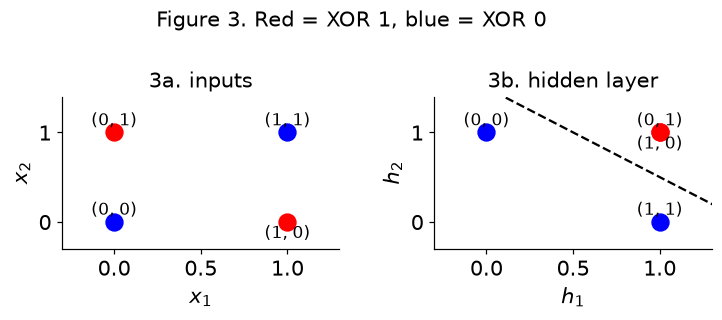

In [17]:
# c.8
# why the hidden layer helps: it moves the four inputs to new points
# h = σ(W x + b). In the input plane no line separates the XOR
# classes; in the hidden plane one line does
hid = np.array([layer(Wh, bh)(x) for x in inputs])
# labels: (0,1) and (1,0) land on the same hidden point, so one
# label goes above it and one below
offs = [0.13, 0.13, -0.13, 0.13]
def pts(ax, ps):
    for k in range(4):
        ax.plot(*ps[k], "o", ms=11, color="red" if xorY[k] else "blue")
        ax.text(ps[k][0], ps[k][1] + offs[k], str(tuple(int(v) for v in inputs[k])),
                ha="center", va="center", fontsize=figFont - 3)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(2 * wHalf + 1, wHalf))
pts(a1, inputs)
a1.set(xlim=(-0.3, 1.3), ylim=(-0.3, 1.4), xlabel="$x_1$", ylabel="$x_2$", title="3a. inputs")
pts(a2, hid)
a2.plot([-0.2, 1.7], [1.7, -0.2], "k--")
a2.set(xlim=(-0.3, 1.3), ylim=(-0.3, 1.4), xlabel="$h_1$", ylabel="$h_2$", title="3b. hidden layer")
fig.suptitle("Figure 3. Red = XOR 1, blue = XOR 0", fontsize=figFont)
fig.tight_layout()
plt.show()

**Theorem 2 (universal approximation).** One hidden layer of σ neurons is already enough to approximate any continuous function on a cube as closely as wanted, given enough neurons (Cybenko [3]; Theorem M2 of [1]). Depth is a matter of efficiency, not of possibility.

## 4. Measuring the error: the loss

To learn, the network needs a number that says how wrong it is. For M examples ${x}_{m}$ with answers ${y}_{m}$, the squared error averages the squared distance between output and answer (the factor 1/2 only simplifies the derivative):

$$
L = \frac{1}{2 M} {\sum}_{m = 1}^{M} {\Vert {a}^{L} ( {x}_{m} ) - {y}_{m} \Vert}^{2} \quad  \tag{8}
$$

For classification into K classes, the answers are written one-hot: y has a 1 in the position of the true class and 0 elsewhere. The output layer uses softmax, which turns K numbers into K probabilities, and the loss is the cross-entropy, the average of minus the log of the probability given to the true class. Softmax outputs are positive and add up to 1:

$$
{a}_{k} = \frac{{e}^{{z}_{k}}}{\sum_{j} {e}^{{z}_{j}}} \quad  \tag{9}
$$

$$
L = - \frac{1}{M} {\sum}_{m = 1}^{M} \sum_{k} {y}_{mk} \  \log  \  {a}_{mk} \quad  \tag{10}
$$

## 5. Backpropagation: the chain rule, organized

Training changes every weight a little in the direction that lowers the loss, so it needs the gradient: the derivative of L with respect to every entry of every ${W}^{l}$ and ${b}^{l}$. Backpropagation [4] computes all of them in one backward sweep, at about the cost of one forward pass; textbook accounts are in [5] and [6].

**Theorem 3 (backpropagation).** Let ${\delta}^{l}$ = ∂L/∂${z}^{l}$ be the derivative of the loss with respect to the weighted sums of layer l. Then ${\delta}^{L}$ is given by Eq. (11): the first form for a σ output with the squared error, the second for a softmax output with the cross-entropy and for a linear output with the squared error. The earlier ${\delta}^{l}$ follow from the backward recursion Eq. (12), and the gradients from Eq. (13). Here ⊙ is the Hadamard product: entry-by-entry multiplication of two vectors (or matrices) of the same shape: entry i of u ⊙ v is ${u}_{i}$ ${v}_{i}$.

$$
{\delta}^{L} = ( {a}^{L} - y ) \odot {\sigma}^{\prime} ( {z}^{L} ) \quad \text{or} \quad  {\delta}^{L} = {a}^{L} - y \quad  \tag{11}
$$

$$
{\delta}^{l} = ( {( {W}^{l + 1} )}^{T} \  {\delta}^{l + 1} ) \odot {\sigma}^{\prime} ( {z}^{l} ) , l = L - 1 , \ldots , 1 \quad  \tag{12}
$$

$$
\frac{\partial L}{\partial {W}^{l}} = {\delta}^{l} \  {( {a}^{l - 1} )}^{T} , \frac{\partial L}{\partial {b}^{l}} = {\delta}^{l} \quad  \tag{13}
$$

**Proof.** At the output, L depends on ${z}^{L}$ through ${a}^{L}$ = σ(${z}^{L}$), so the chain rule gives (${a}^{L}$ - y) times σ′(${z}^{L}$) for the squared error; for softmax with cross-entropy the factors combine and leave ${a}^{L}$ - y. For an earlier layer, ${z}^{l}$ affects L only through the weighted sums of the next layer, which are W σ(${z}^{l}$) + b with that layer's W and b. Differentiating this composition gives the transpose of the next layer's W applied to the next layer's δ, times σ′(${z}^{l}$) entrywise, which is Eq. (12). Finally ${z}^{l}$ depends linearly on ${W}^{l}$ and ${b}^{l}$, with coefficients the previous activations and 1, which gives Eq. (13). For M samples the gradients are averaged. ∎

Read Eq. (12) as Figure M3 read backwards: the error signal δ flows from the output to the input along the same arrows, multiplied by the same weights, now transposed.

The operator ⊙ is the Hadamard product, also called the entrywise or Schur product. It multiplies two vectors or matrices of the same shape entry by entry, with no sums: entry i of u ⊙ v is ${u}_{i}$ ${v}_{i}$, and entry (i, j) of A ⊙ B is ${A}_{ij}$ ${B}_{ij}$. For example (1, 2, 3) ⊙ (4, 5, 6) = (4, 10, 18), whereas the dot product of the same vectors is the single number 32. In Eq. (12) it applies to each neuron its own factor σ′(${z}_{i}$): neuron i passes back only as much error as its σ is sensitive at its own ${z}_{i}$. In NumPy two arrays of the same shape multiplied with * are multiplied entrywise, so A * (1 - A) and d * A * (1 - A) in the code are exactly ⊙ products, while @ is the matrix product.

Cell c.9 programs Eqs. (6), (8)–(13) for any number of layers, in the row convention of Eq. (5).

In [18]:
# c.9
# a network is a list of layers (W, b). In the code the M samples are
# the rows of a matrix, so Eq. (6) z = W a + b becomes Z = A Wᵀ + b
sigma = logistic_sigmoid
identity = lambda Z: Z
# softmax row by row; subtracting the row maximum avoids overflow
def softmax(Z):
    ez = np.exp(Z - Z.max(axis=1, keepdims=True))
    return ez / ez.sum(axis=1, keepdims=True)
# affine map of a layer, rows = samples: A Wᵀ + b in every row
def affine(layer_, A):
    W, b = layer_
    return A @ W.T + b
# forward pass: keep every A^(l); out is the output activation
def forward(net, X, out):
    As = [np.asarray(X, dtype=float)]
    for l, layer_ in enumerate(net, 1):
        As.append((out if l == len(net) else sigma)(affine(layer_, As[-1])))
    return As
# three kinds of output: "mse" = σ output with squared error,
# "lin" = linear output with squared error, "ce" = softmax output
# with cross-entropy; the losses are Eqs. (8) and (10)
loss = {"mse": lambda P, Y: np.sum((P - Y)**2) / (2 * len(Y)),
        "lin": lambda P, Y: np.sum((P - Y)**2) / (2 * len(Y)),
        "ce": lambda P, Y: -np.sum(Y * np.log(P + 1e-15)) / len(Y)}
outAct = {"mse": sigma, "lin": identity, "ce": softmax}
# backpropagation, Theorem 3: the output delta of Eq. (11), then
# Eq. (12) layer by layer, and the gradients of Eq. (13)
def backprop(net, X, Y, kind):
    # forward pass, keeping the activations of every layer
    As = forward(net, X, outAct[kind])
    # Eq. (11): σ output adds the factor σ′; "lin" and "ce" do not
    d = (As[-1] - Y) * As[-1] * (1 - As[-1]) if kind == "mse" else As[-1] - Y
    d = d / len(Y)
    # from the last layer back: gradients of W and b, Eq. (13),
    # then δ of the layer before, Eq. (12)
    g = []
    for l in range(len(net), 0, -1):
        g.insert(0, (d.T @ As[l - 1], d.sum(axis=0)))
        if l > 1:
            d = (d @ net[l - 1][0]) * As[l - 1] * (1 - As[l - 1])
    return loss[kind](As[-1], Y), g
# random start: normal weights with sd 1/√(inputs), zero biases
def initNet(sizes, rng):
    return [(rng.normal(0, 1 / np.sqrt(sizes[l]), (sizes[l + 1], sizes[l])), np.zeros(sizes[l + 1]))
            for l in range(len(sizes) - 1)]
# arithmetic on whole networks, like net - eta g in Wolfram Language
def nmap(f, *nets):
    return [tuple(f(*arrs) for arrs in zip(*layers)) for layers in zip(*nets)]
print("forward, backprop and initNet defined")

forward, backprop and initNet defined


A backpropagation program can be wrong in ways that still learn a little, so it is checked three ways on a small random network: against symbolic differentiation with SymPy and against central finite differences of the loss.

*Table 6. Backpropagation against SymPy and against finite differences.*

In [19]:
# c.10
# check backprop three ways on a small random 2-3-2 network
rng = np.random.default_rng(4)
netT = initNet([2, 3, 2], rng); XT = rng.uniform(-1, 1, (5, 2))
YT = rng.uniform(0, 1, (5, 2))
# the gradients by backprop, Theorem 3
lossT, gT = backprop(netT, XT, YT, "mse")
# 1: symbolic differentiation with SymPy on symbolic weights
symNet = [(sp.Matrix(3, 2, lambda i, j: sp.Symbol(f"wa_{i}{j}")), sp.Matrix(3, 1, lambda i, j: sp.Symbol(f"ba_{i}"))),
          (sp.Matrix(2, 3, lambda i, j: sp.Symbol(f"wb_{i}{j}")), sp.Matrix(2, 1, lambda i, j: sp.Symbol(f"bb_{i}")))]
symbols = [s for W, b in symNet for s in list(W) + list(b)]
values = [v for W, b in netT for v in list(W.ravel()) + list(b)]
sg = lambda z: 1 / (1 + sp.exp(-z))
symLoss = 0
for x, y in zip(XT, YT):
    a = sp.Matrix(x)
    for W, b in symNet:
        a = (W * a + b).applyfunc(sg)
    symLoss += sum((a[i] - y[i])**2 for i in range(2))
symLoss = symLoss / (2 * len(YT))
gradFun = sp.lambdify(symbols, [sp.diff(symLoss, s) for s in symbols], "numpy")
gD = np.array(gradFun(*values))
flatG = lambda g: np.concatenate([np.concatenate([W.ravel(), b]) for W, b in g])
# 2: central finite differences on every weight
flat = flatG(netT)
def shape(v):
    out, i = [], 0
    for W, b in netT:
        out.append((v[i:i + W.size].reshape(W.shape), v[i + W.size:i + W.size + b.size]))
        i += W.size + b.size
    return out
lossAt = lambda v: loss["mse"](forward(shape(v), XT, sigma)[-1], YT)
eps = 1e-6
gFD = np.array([(lossAt(flat + eps * e) - lossAt(flat - eps * e)) / (2 * eps) for e in np.eye(len(flat))])
# all differences should be at rounding level
table([["comparison", "largest difference"],
       ["backprop vs SymPy", sci(np.abs(flatG(gT) - gD).max())],
       ["backprop vs finite differences", sci(np.abs(flatG(gT) - gFD).max())],
       ["largest gradient entry", sci(np.abs(flatG(gT)).max())]], "Table 6")

comparison,largest difference
backprop vs SymPy,1.4 × 10-17
backprop vs finite differences,1.4 × 10-11
largest gradient entry,3.0 × 10-2


## 6. Gradient descent: training XOR

Gradient descent repeats one step: compute the gradient by backpropagation and move every weight a small distance η, the learning rate, against it:

$$
{W}^{l} \leftarrow {W}^{l} - \eta \  \frac{\partial L}{\partial {W}^{l}} , {b}^{l} \leftarrow {b}^{l} - \eta \  \frac{\partial L}{\partial {b}^{l}} \quad  \tag{14}
$$

In [20]:
# c.11
# gradient descent, Eq. (14): step every W and b against its gradient;
# keep a snapshot (epoch, loss, network) every `every` epochs
def train(net0, X, Y, kind, eta, epochs, every):
    net, hist = net0, []
    # each epoch: loss and gradient by backprop, keep a snapshot,
    # then the step W ← W - η ∂L/∂W for every layer at once
    for e in range(1, epochs + 1):
        l, g = backprop(net, X, Y, kind)
        if (e - 1) % every == 0:
            hist.append((e - 1, l, net))
        net = nmap(lambda w, gw: w - eta * gw, net, g)
    hist.append((epochs, backprop(net, X, Y, kind)[0], net))
    return hist
print("train defined")

train defined


A 2-3-1 network with random starting weights is trained on the four XOR examples, with the squared error and η = 4. One pass over the data is an epoch.

*Table 7. The loss and the four outputs during training. The network first drifts towards 0.5 everywhere, one of the single-neuron answers of Table 4, then breaks the symmetry around epoch 300 and settles on XOR.*

In [21]:
# c.12
# train a 2-3-1 network on XOR from random weights
rng = np.random.default_rng(7)
xorX = inputs.astype(float); xorT = xorY[:, None].astype(float)
# η = 4, 3000 epochs, a snapshot every 25 epochs
histX = train(initNet([2, 3, 1], rng), xorX, xorT, "mse", 4., 3000, 25)
# the loss and the four outputs at a few snapshots
table([["epoch", "loss", "out (0,0)", "out (0,1)", "out (1,0)", "out (1,1)"]] +
      [[histX[k][0], sci(histX[k][1])] + [nform(v, 3) for v in forward(histX[k][2], xorX, sigma)[-1].ravel()]
       for k in [0, 4, 8, 12, 20, 40, 80, len(histX) - 1]], "Table 7")

epoch,loss,"out (0,0)","out (0,1)","out (1,0)","out (1,1)"
0,1.3 × 10-1,0.565,0.548,0.562,0.545
100,1.2 × 10-1,0.483,0.495,0.509,0.512
200,1.1 × 10-1,0.385,0.522,0.549,0.559
300,8.1 × 10-2,0.218,0.602,0.656,0.572
500,9.0 × 10-3,0.11,0.869,0.87,0.161
1000,1.4 × 10-3,0.0477,0.949,0.949,0.06
2000,4.6 × 10-4,0.0282,0.97,0.971,0.0341
3000,2.7 × 10-4,0.0218,0.977,0.978,0.0259


*Diagram 2. The trained 2-3-1 XOR network. Compare it with the hand-built network of Figure 2: training has found its own solution, with three hidden neurons instead of two.*

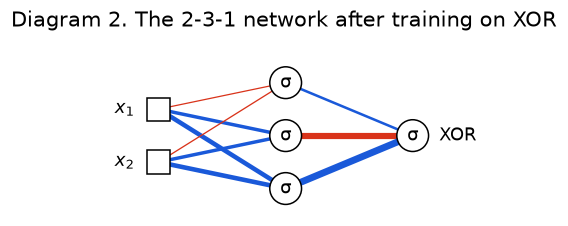

In [22]:
# c.12b
# the trained XOR network: red = positive weight, blue = negative,
# thicker = larger
diagram([([2, 3, 1], histX[-1][2], ["$x_1$", "$x_2$"], ["XOR"], "σ", "")],
        "Diagram 2. The 2-3-1 network after training on XOR")

Backpropagation is matrix algebra too. With the examples as rows, the δ of a layer is an M × (neurons) matrix, the gradient of W is δᵀ times the activations of the layer before, and the δ of the layer before is δ W, multiplied entrywise by σ′, Eqs. (11)–(13) in the row convention. Here are all of these matrices for the first step of the training of Table 7.

*Table 7b. One backward pass of the 2-3-1 network at epoch 0, for the 4 XOR examples. The last line checks that the matrix formulas give exactly the gradient computed by backprop in cell c.9.*

In [23]:
# c.12c
# backpropagation in matrices, on the first training step of Table 7:
# the 2-3-1 network at epoch 0, all 4 XOR examples. Rows are
# examples, so every δ is 4 × (neurons of its layer)
net0 = histX[0][2]
A0, A1, A2 = forward(net0, xorX, sigma)
d2 = (A2 - xorT) * A2 * (1 - A2) / 4               # Eq. (11), 4×1
gW2 = d2.T @ A1; gb2 = d2.sum(axis=0)               # Eq. (13)
d1 = (d2 @ net0[1][0]) * A1 * (1 - A1)             # Eq. (12), 4×3
gW1 = d1.T @ A0; gb1 = d1.sum(axis=0)
table([["quantity", "size", "value"],
       ["output δ = (a - y) ⊙ a ⊙ (1 - a)/M", "4×1", mat(d2)],
       ["∂L/∂W (output) = δᵀ A (hidden)", "1×3", mat(gW2)],
       ["hidden δ = (δ W) ⊙ A ⊙ (1 - A)", "4×3", mat(d1)],
       ["∂L/∂W (hidden) = δᵀ X", "3×2", mat(gW1)],
       ["∂L/∂b (hidden) = column sums of δ", "3", col(gb1)],
       ["same as backprop of c.9?", "", np.array_equal(gW1, backprop(net0, xorX, xorT, "mse")[1][0][0])]],
      "Table 7b. One backward pass in matrix form")

*Figure 4. Move the slider through the training (shown after training). Left: the output of the network over the plane, with the four inputs (white = answer 1). Right: the loss, with the current epoch marked.*

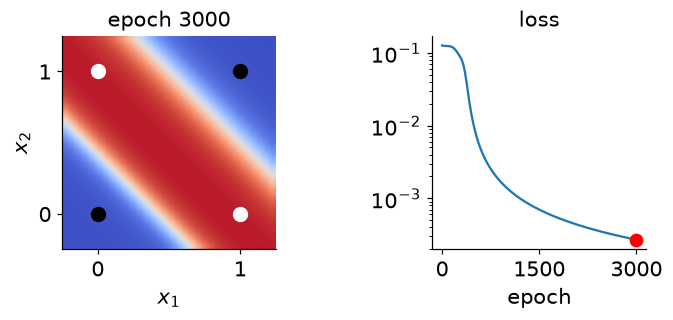

In [24]:
# c.13
# precompute, for every snapshot, the network output on a grid of
# the plane; the slider below then only looks values up
gr = np.arange(-0.25, 1.2501, 0.05)
gridPts = np.array([(a, b) for a in gr for b in gr])
surfX = [forward(h[2], gridPts, sigma)[-1].reshape(len(gr), len(gr)).T for h in histX]
# epoch and loss of every snapshot, for the loss curve
lossX = np.array([(h[0], h[1]) for h in histX])
def xorSurface(ax, k, title):
    ax.imshow(surfX[k - 1], origin="lower", extent=(-0.25, 1.25, -0.25, 1.25), cmap="coolwarm",
              vmin=0, vmax=1, interpolation="bilinear")
    for j in range(4):
        ax.plot(*inputs[j], "o", ms=9, color="white" if xorY[j] else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="$x_1$", ylabel="$x_2$", title=title)
# one view: output over the plane (left), loss with the current
# epoch in red (right)
def xorView(fig, k):
    fig.clf()
    a1, a2 = fig.subplots(1, 2)
    xorSurface(a1, k, f"epoch {int(lossX[k - 1, 0])}")
    a2.semilogy(lossX[:, 0], lossX[:, 1])
    a2.plot(*lossX[k - 1], "o", color="red", ms=8)
    a2.set(xticks=[0, 1500, 3000], xlabel="epoch", title="loss", box_aspect=1)
    fig.tight_layout()
manipulate(xorView, (2 * wHalf + 1, wHalf * 1.05), {"k": slider("snapshot", 1, len(histX))},
           {"k": len(histX)})

*Figure 5. The same training as an animation of the output surface. Press play.*

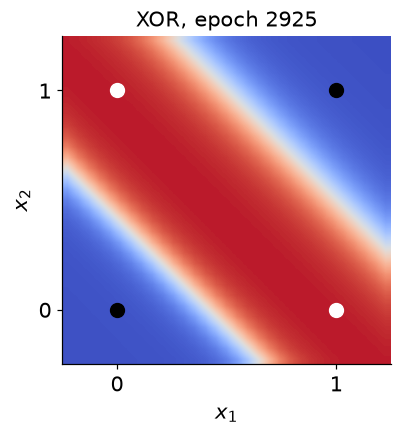

In [25]:
# c.14
# the same training as an animation: press play (it never starts by itself)
xorPick = list(range(1, 41)) + list(range(42, len(histX) + 1, 4))
def xorFrame(fig, f):
    fig.clf()
    xorSurface(fig.subplots(), xorPick[f - 1], f"XOR, epoch {int(lossX[xorPick[f - 1] - 1, 0])}")
fXor, boxXor = player("frame", 1, len(xorPick), fps=8)
manipulate(xorFrame, (wHalf * 1.3, wHalf * 1.3), {"f": fXor}, {"f": len(xorPick)}, [boxXor])

▶ **Video:** [XOR-training.mp4](videos/XOR-training.mp4), the XOR training of Figure 5.

## 7. A neuron learns Celsius to Fahrenheit

The simplest learning problem everyone knows the answer to: temperatures in Celsius and in Fahrenheit. The rule is F = 1.8 C + 32, but the network is not told; it only sees eight pairs.

*Table 8. Eight familiar temperatures.*

In [26]:
# c.15
# temperatures everybody knows, in °C and °F
temps = [("cold winter day", -40), ("freezer", -18), ("water freezes", 0), ("spring day", 10),
         ("room", 21), ("body", 37), ("hot summer day", 45), ("water boils", 100)]
# the exact rule, which the neuron is not told
fahr = lambda c: 9 / 5 * c + 32
table([["", "°C", "°F"]] + [[n, c, nform(fahr(c), 6)] for n, c in temps], "Table 8")

,°C,°F
cold winter day,-40,-40
freezer,-18,-0.4
water freezes,0,32
spring day,10,50
room,21,69.8
body,37,98.6
hot summer day,45,113
water boils,100,212


One neuron with no activation function, F = w u + b, is enough, because the rule is a straight line. The input is u = C/100 so that both parameters are of a similar size; the slope per degree is then w/100. The loss and its gradient are

$$
\begin{gathered}L ( w , b ) = \frac{1}{2 M} {\sum}_{m = 1}^{M} {( w \  {u}_{m} + b - {F}_{m} )}^{2} , {u}_{m} = \frac{{C}_{m}}{100} \\ \frac{\partial L}{\partial w} = \frac{1}{M} \sum_{m} {r}_{m} \  {u}_{m} , \frac{\partial L}{\partial b} = \frac{1}{M} \sum_{m} {r}_{m} , {r}_{m} = w \  {u}_{m} + b - {F}_{m}\end{gathered} \quad  \tag{15}
$$

which is Eq. (11) with a linear output: the error signal is just the residual ${r}_{m}$.

*Table 9. Learning the rule from w = 0, b = 0, with η = 0.5. After 200 epochs the neuron has found F = 1.8 C + 32 to all digits shown.*

In [27]:
# c.16
# one linear neuron, F = w (C/100) + b: no hidden layer, no σ. The
# input is divided by 100 so that w and b are of similar size; then
# the slope per degree is w/100 and should come out as 9/5 = 1.8
# inputs u = C/100 and targets F, one example per row
cX = np.array([[c / 100] for n, c in temps])
fY = np.array([[fahr(c)] for n, c in temps])
# start from w = b = 0; η = 0.5, 400 epochs
histT = train([(np.zeros((1, 1)), np.zeros(1))], cX, fY, "lin", 0.5, 400, 2)
# read w and b out of a snapshot
wb = lambda h: (h[2][0][0][0, 0], h[2][0][1][0])
table([["epoch", "loss", "slope w/100", "intercept b"]] +
      [[histT[k][0], nform(histT[k][1]), nform(wb(histT[k])[0] / 100), nform(wb(histT[k])[1])]
       for k in [0, 1, 5, 10, 25, 50, 100, len(histT) - 1]], "Table 9")

epoch,loss,slope w/100,intercept b
0,4839,0,0
2,1721,0.3657,48.13
10,439.6,1.063,48.83
20,88.65,1.469,39.58
50,0.7271,1.77,32.69
100,0.0002425,1.799,32.01
200,2.699e-11,1.8,32
400,3.413e-25,1.8,32


*Diagram 3. The trained temperature neuron: weight 180 on C/100, that is 1.8 per degree, and bias 32.*

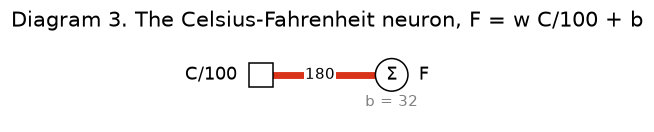

In [28]:
# c.16b
# the temperature neuron after training: Σ marks a linear output,
# no σ is applied
diagram([([1, 1], histT[-1][2], ["C/100"], ["F"], "Σ", "")],
        "Diagram 3. The Celsius-Fahrenheit neuron, F = w C/100 + b")

*Table 9b. The trained temperature neuron as a matrix product. All matrices are 1 × 1: the smallest case of Eq. (4).*

In [29]:
# c.16c
# the trained temperature neuron in matrix form: here every matrix is
# 1×1, so the product is an ordinary product
wT, bT = histT[-1][2][0]
table([["C", "F = w u + b,  u = C/100"]] +
      [[f"{c} °C", row(mat(wT), " ", col([c / 100]), " + ", col(bT), " = ", col(wT @ [c / 100] + bT))]
       for c in (37, 100)], "Table 9b. The temperature neuron as a matrix product")

With only two parameters the loss can be drawn as a landscape over the (w, b) plane. Its valley is a long, tilted ellipse: lowering w can be traded for raising b. Gradient descent first runs steeply downhill, overshooting in b, and then slides along the valley floor to the bottom at (180, 32).

*Figure 6. Move the slider (shown at the end of the walk). Left: the path of (w, b) on the contours of the loss; the red dot is the answer. Right: the current line against the eight temperatures.*

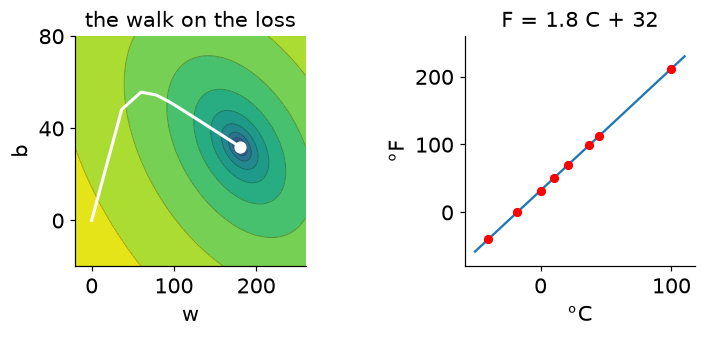

In [30]:
# c.17
# the loss as a landscape over (w, b), Eq. (15); gradient descent
# walks downhill on it. Move the slider to follow the walk
lossWB = lambda w, b: np.mean((w * cX[:, 0, None, None] + b - fY[:, 0, None, None])**2, axis=0) / 2
# the (w, b) of every snapshot: the path of gradient descent
pathT = np.array([wb(h) for h in histT])
# contours of log10 of the loss; the red dot is the answer (180, 32)
Wg, Bg = np.meshgrid(np.linspace(-20, 260, 160), np.linspace(-20, 80, 120))
landZ = np.log10(lossWB(Wg, Bg) + 0.1)
# one view: the path on the loss (left), the line against the data (right)
def celsiusView(fig, k):
    fig.clf()
    a1, a2 = fig.subplots(1, 2)
    a1.contourf(Wg, Bg, landZ, levels=14, cmap="viridis")
    a1.contour(Wg, Bg, landZ, levels=14, colors="k", alpha=0.3, linewidths=0.6)
    a1.plot(180, 32, "o", color="red", ms=6)
    a1.plot(pathT[:k, 0], pathT[:k, 1], color="white", lw=2)
    a1.plot(*pathT[k - 1], "o", color="white", ms=7)
    a1.set(xticks=[0, 100, 200], yticks=[0, 40, 80], xlabel="w", ylabel="b",
           title="the walk on the loss", box_aspect=1)
    c = np.linspace(-50, 110, 2)
    a2.plot(c, pathT[k - 1, 0] * c / 100 + pathT[k - 1, 1])
    a2.plot(100 * cX[:, 0], fY[:, 0], "o", color="red", ms=5)
    a2.set(ylim=(-80, 260), xlabel="°C", ylabel="°F", box_aspect=1,
           title=f"F = {pathT[k - 1, 0] / 100:.3g} C + {pathT[k - 1, 1]:.3g}")
    fig.tight_layout()
manipulate(celsiusView, (2 * wHalf + 1.2, wHalf * 1.1), {"k": slider("step", 1, len(pathT))},
           {"k": len(pathT)})

## 8. Balancing a stick on a moving cart

Balance a broom upright on the palm of your hand: you keep it up by moving your hand under it, a little ahead of where it falls. The cart-pole is the same problem on a rail: a stick of length 1 m (mass 0.1 kg) stands on a hinge on a cart (1 kg), and the only control is a horizontal force u on the cart, at most 10 N either way. The state is s = (x, v, θ, ω): cart position and speed, the angle of the stick from upright and its angular speed. Newton's laws give [7], with g = 9.81 m/s² and l = 0.5 m the half length of the stick,

$$
\begin{gathered}\frac{d \omega}{d t} = \frac{g \  \sin  \  \theta - \cos  \  \theta \  f}{l \  ( \frac{4}{3} - \frac{{m}_{p} \  {\cos }^{2} \  \theta}{{m}_{c} + {m}_{p}} )} , \frac{d \theta}{d t} = \omega \\ f = \frac{u + {m}_{p} \  l \  {\omega}^{2} \  \sin  \  \theta}{{m}_{c} + {m}_{p}} , \frac{d v}{d t} = f - \frac{{m}_{p} \  l \  \frac{d \omega}{d t} \  \cos  \  \theta}{{m}_{c} + {m}_{p}} , \frac{d x}{d t} = v\end{gathered} \quad  \tag{16}
$$

Upright is an equilibrium, but an unstable one: left alone, a 17° tilt becomes a fallen stick in under a second. It is a classic test of control and of learning, because the controller must act continuously and every mistake grows.

### A teacher and a student

Control theory gives a good balancing rule. Near upright the equations are nearly linear, and for linear equations the LQR (linear quadratic regulator) finds the gains K of the best linear rule u = -K·s; SciPy's solve_continuous_are solves the Riccati equation that gives them (in Wolfram Language: LQRegulatorGains). A real motor has a limited force, so the teacher saturates smoothly at 10 N:

$$
u = {u}_{\max } \  \tanh  ( - \frac{K \cdot s}{{u}_{\max }} ) , s = ( x , v , \theta , \omega ) , {u}_{\max } = 10 \  N \quad  \tag{17}
$$

The teacher is a nonlinear function of four inputs, exactly the kind of function a network with one hidden layer can learn (Theorem 2). The student is a 4-8-1 network with σ hidden neurons and a linear output, trained with the squared error on 3000 random states, each labelled with the force the teacher would apply. This is called imitation learning; Widrow and Smith [8] trained an early network to balance a broom this way in 1964.

*Table 10. Four of the 3000 training examples, and the LQR gains of the teacher.*

In [31]:
# c.18
# the cart-pole: a stick of length 1 m on a cart that can be pushed
# left or right. State s = (x, v, θ, ω): cart position and speed,
# stick angle from upright and its angular speed
g0, mc, mp, length = 9.81, 1., 0.1, 0.5     # length = half stick length
def rhs(st, u, lib=np):
    x, v, th, om = st
    s, c = lib.sin(th), lib.cos(th)
    f = (u + mp * length * om**2 * s) / (mc + mp)
    al = (g0 * s - c * f) / (length * (sp.Rational(4, 3) if lib is sp else 4 / 3) - length * mp * c**2 / (mc + mp))
    return [v, f - mp * length * al * c / (mc + mp), om, al]
# the teacher: an LQR controller for the straightened (linear)
# equations, with the motor limited to |u| <= 10 N
xs_, u_ = sp.symbols("x v th om"), sp.Symbol("u")
jac = sp.Matrix(rhs(xs_, u_, sp)).jacobian(list(xs_) + [u_]).subs({**{s: 0 for s in xs_}, u_: 0})
Alin = np.array(jac[:, :4], dtype=float); Blin = np.array(jac[:, 4], dtype=float)
Q, R = np.diag([1., 1., 10., 1.]), np.array([[0.1]])
Pare = solve_continuous_are(Alin, Blin, Q, R)       # the Riccati equation of LQR
K = (np.linalg.solve(R, Blin.T @ Pare))[0]          # u = -K·s, as LQRegulatorGains gives it
umax = 10.
teacher = lambda s: umax * np.tanh(-(np.asarray(s) @ K) / umax)
# 3000 random states as examples; inputs and targets scaled to ~1
scale = np.array([1., 2., 0.5, 2.])
rng = np.random.default_rng(3)
states = rng.uniform(-1, 1, (3000, 4)) * scale
cpX = states / scale
cpY = (teacher(states) / umax)[:, None]
table([["state (x, v, θ, ω)", "teacher force u (N)"]] +
      [[nform(states[k], 2), nform(teacher(states[k]), 3)] for k in range(4)] +
      [["LQR gains K", nform(K, 3)]], "Table 10")

"state (x, v, θ, ω)",teacher force u (N)
"(-0.83, -1.1, 0.3, 0.33)",7.74
"(-0.81, -0.27, -0.021, -1.4)",-9.79
"(0.47, -1.5, -0.11, 0.067)",-8.39
"(-0.14, 0.35, 0.24, 1.8)",9.99
LQR gains K,"(-3.16, -5.91, -49.5, -12.8)"


The network is never shown a moving cart: it only learns a function from states to forces. The test is to put it in control. The cart starts at rest with the stick tilted 17°, and the equations (16) are integrated with the Runge-Kutta method, step 0.02 s, with the force chosen by the network at every step.

*Table 11. The loss during training, and what happens when the network at that epoch drives the cart. Each epoch it holds the stick a little longer, and from about epoch 100 it balances.*

In [32]:
# c.19
# a 4-8-1 network imitates the teacher: σ hidden layer, linear
# output, squared error ("lin"). Then the network alone drives the
# cart and we see whether the stick stays up
rng = np.random.default_rng(5)
histC = train(initNet([4, 8, 1], rng), cpX, cpY, "lin", 0.5, 4000, 10)
def ctrl(net):
    (W1_, b1_), (W2_, b2_) = net
    return lambda s: float(np.clip(umax * (W2_ @ sigma(W1_ @ (s / scale) + b1_) + b2_)[0], -umax, umax))
dt = 0.02
def rk4(f):
    def stepper(s):
        u = f(s)
        k1 = np.array(rhs(s, u)); k2 = np.array(rhs(s + dt / 2 * k1, u))
        k3 = np.array(rhs(s + dt / 2 * k2, u)); k4 = np.array(rhs(s + dt * k3, u))
        return s + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return stepper
fallen = lambda s: abs(s[2]) > np.pi / 2
# 6 s of motion from a 17° tilt; a fallen stick stays fallen
s0 = np.array([0., 0., 0.3, 0.])
def sim(f, s1, n):
    tr, step = [np.asarray(s1, dtype=float)], rk4(f)
    for _ in range(n):
        tr.append(tr[-1] if fallen(tr[-1]) else step(tr[-1]))
    return np.array(tr)
def fate(tr):
    down = [fallen(s) for s in tr]
    return "balances" if not any(down) else f"falls at t = {dt * down.index(True):.2g} s"
table([["epoch", "loss", "the stick, network in control"]] +
      [[histC[k][0], nform(histC[k][1], 3), fate(sim(ctrl(histC[k][2]), s0, 300))]
       for k in [0, 2, 4, 10, 20, 100, len(histC) - 1]], "Table 11")

epoch,loss,"the stick, network in control"
0,0.688,falls at t = 0.42 s
20,0.211,falls at t = 0.82 s
40,0.0853,falls at t = 1.7 s
100,0.0326,balances
200,0.0277,balances
1000,0.00385,balances
4000,0.000411,balances


*Diagram 4. The trained balancing network. The thickest lines leave θ and ω: the tilt of the stick and how fast it is falling matter most, as for a person balancing a broom.*

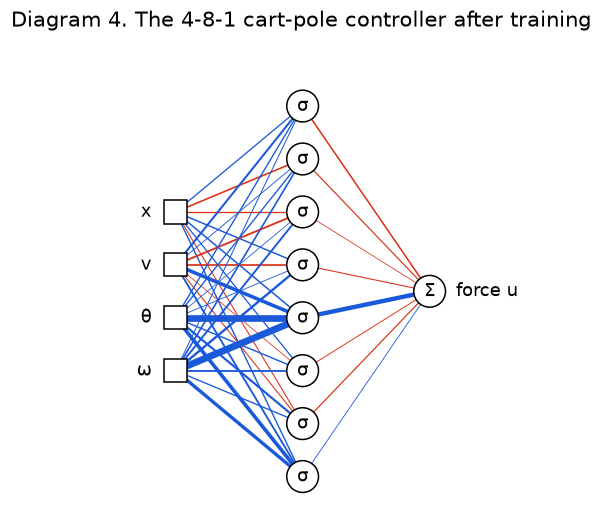

In [33]:
# c.19b
# the trained balancing network: the four state variables in, the
# force out
diagram([([4, 8, 1], histC[-1][2], ["x", "v", "θ", "ω"], ["force u"], "Σ", "")],
        "Diagram 4. The 4-8-1 cart-pole controller after training")

One decision of the controller, written out: the hidden layer multiplies the 8 × 4 matrix W by the scaled state, adds the 8 biases and applies σ; the output layer multiplies the 1 × 8 row W by these 8 values. The network's force is within 0.03 N of the teacher's.

*Table 11b. The trained controller as matrix products, for the start state of Table 11 (stick tilted 17°).*

In [34]:
# c.19c
# one decision of the trained controller, in matrices: the start
# state of Table 11, tilted 17°. W1 is 8×4 (8 hidden neurons × 4
# inputs), W2 is 1×8
(W1c, b1c), (W2c, b2c) = histC[-1][2]
sIn = s0 / scale                       # scaled input, 4×1
z1c = W1c @ sIn + b1c; h1c = sigma(z1c)
z2c = W2c @ h1c + b2c
mtable([
    ("scaled state s/scale = (x, v, θ, ω)/(1, 2, 0.5, 2)", col(sIn)),
    ("hidden layer:  z = W s + b", row(mat(W1c), " ", col(sIn), " + ", col(b1c), " = ", col(z1c))),
    ("h = σ(z)", row("σ", col(z1c), " = ", col(h1c))),
    ("output layer:  W h + b", row(mat(W2c), " ", col(h1c), " + ", col(b2c), " = ", col(z2c))),
    ("force u = 10 × output", f"{10 * z2c[0]:.3g} N   (the teacher would push {teacher(s0):.3g} N)")],
    "Table 11b. One decision of the controller as matrix products")

*Figure 7. Pick a training snapshot with the top slider and press play on time (shown for the trained network at t = 0). Top: the cart, the stick and the force (blue arrow). Bottom: the angle of the stick over 6 s; 90° means it has fallen. The first snapshots drop the stick, later ones catch it, and the trained network brings it upright and the cart back towards the centre.*

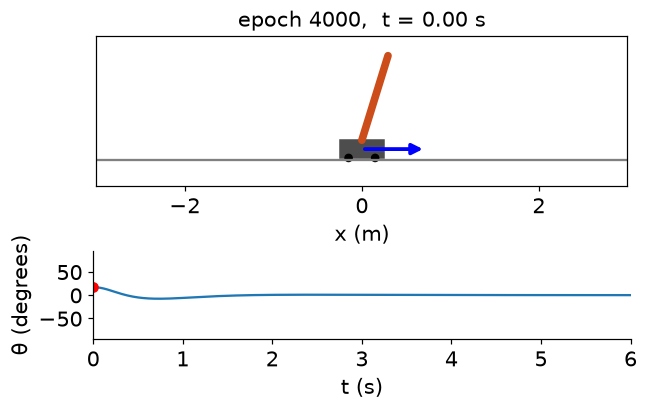

In [35]:
# c.20
# watch it learn: pick a training snapshot, then press play on time
pick = list(range(1, 22)) + [26, 31, 41, 61, 101, 201, len(histC)]
# 6 s of motion for each chosen snapshot, and its forces
trajC = [sim(ctrl(histC[k - 1][2]), s0, 300) for k in pick]
forceC = [[0. if fallen(s) else ctrl(histC[pick[j] - 1][2])(s) for s in trajC[j]] for j in range(len(pick))]
# draw rail, cart, stick (length 2 length) and force arrow
def cartPole(ax, st, u):
    x, v, th, om = st
    ax.plot([-3, 3], [0, 0], color="gray")
    ax.add_patch(plt.Rectangle((x - 0.25, 0.02), 0.5, 0.2, color=(0.3,) * 3))
    for dx in (-0.15, 0.15):
        ax.add_patch(plt.Circle((x + dx, 0.02), 0.04, color="black"))
    ax.plot([x, x + 2 * length * np.sin(th)], [0.22, 0.22 + 2 * length * np.cos(th)],
            color=(0.8, 0.3, 0.1), lw=5, solid_capstyle="round")
    if abs(u) > 0.2:
        ax.annotate("", (x + 0.08 * u, 0.12), (x, 0.12),
                    arrowprops=dict(arrowstyle="-|>", color="blue", lw=2.5))
    ax.set(xlim=(-3, 3), ylim=(-0.3, 1.4), aspect="equal", xticks=[-2, 0, 2], yticks=[], xlabel="x (m)")
    for side in ax.spines.values():          # a frame all round, as in Graphics[..., Frame -> True]
        side.set_visible(True)
# one frame: the cart at time step n, and the angle θ(t)
def cpView(fig, j, n):
    fig.clf()
    a1, a2 = fig.subplots(2, 1, height_ratios=[1.7, 1])
    st = trajC[j - 1][n - 1]
    cartPole(a1, st, forceC[j - 1][n - 1])
    a1.set_title(f"epoch {histC[pick[j - 1] - 1][0]},  t = {dt * (n - 1):.2f} s" +
                 ("   fell" if fallen(st) else ""))
    a2.plot(np.linspace(0, 6, 301), np.degrees(trajC[j - 1][:, 2]))
    a2.plot(dt * (n - 1), np.degrees(st[2]), "o", color="red", ms=6)
    a2.set(xlim=(0, 6), ylim=(-95, 95), xlabel="t (s)", ylabel="θ (degrees)")
    fig.tight_layout()
jSnap = slider("training snapshot", 1, len(pick))
nTime, boxTime = player("time", 1, 301, fps=25)
manipulate(cpView, (wFull, 0.62 * wFull), {"j": jSnap, "n": nTime}, {"j": len(pick), "n": 1},
           [jSnap, boxTime])

▶ **Video:** [CartPole-learning.mp4](videos/CartPole-learning.mp4), the cart-pole at four stages of training.

A controller is only useful if it copes with the unexpected. The trained network is started almost upright, and the stick is hit twice, at t = 1.5 s and at t = 4 s, as if flicked with a finger. Nothing like this was in the training data, yet the network runs the cart under the stick and recovers each time.

*Figure 8. The trained network against two pushes, shown just after the first push. Press play.*

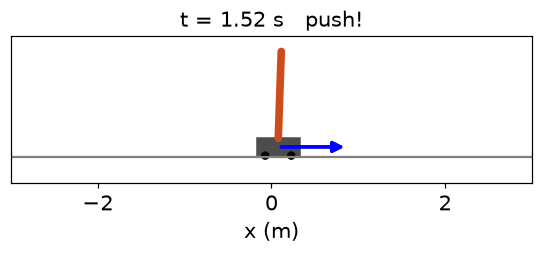

In [36]:
# c.21
# the trained network against pushes it never saw in training: at
# t = 1.5 s and t = 4 s the stick is hit (ω jumps by ±2 rad/s)
netC = histC[-1][2]
# the pushes: ω changes by +2 rad/s at step 75, -2 at step 200
def push(k, s):
    return s + {75: np.array([0, 0, 0, 2.]), 200: np.array([0, 0, 0, -2.])}.get(k, 0)
# each step: the network chooses u, Runge-Kutta moves the
# cart-pole by dt, then a push may hit
stepC = rk4(ctrl(netC))
trajP = [np.array([0., 0., 0.05, 0.])]
for k in range(1, 351):
    trajP.append(push(k, stepC(trajP[-1])))
pushN = list(range(1, 352, 2))
def pushFrame(fig, f):
    fig.clf()
    ax = fig.subplots()
    n = pushN[f - 1]
    cartPole(ax, trajP[n - 1], ctrl(netC)(trajP[n - 1]))
    ax.set_title(f"t = {dt * (n - 1):.2f} s" + ("   push!" if 75 <= n <= 85 or 200 <= n <= 210 else ""))
fPush, boxPush = player("frame", 1, len(pushN), fps=25)
manipulate(pushFrame, (wFull, 0.42 * wFull), {"f": fPush}, {"f": 39}, [boxPush])

▶ **Video:** [CartPole-push-test.mp4](videos/CartPole-push-test.mp4), the push test of Figure 8.

## 9. A network learns the physics of a pendulum

The cart-pole network learned what to do. A network can also learn how a system behaves: a model of its dynamics, which can then be run forward in time like a simulator. Take a pendulum of length 1 m, with time measured so that g/l = 1. Its angle obeys θ″ = a(θ), and we pretend not to know the force law a(θ) = -sin θ: we only have 200 measurements of angle and acceleration, with a little noise. A 1-6-1 network learns a(θ) from them, and the learned pendulum is then run by itself:

$$
\begin{gathered}\frac{d \theta}{d t} = \omega , \frac{d \omega}{d t} = a ( \theta ) \\ E = \frac{{\omega}^{2}}{2} + V ( \theta ) , {V}^{\prime} ( \theta ) = - a ( \theta ) \quad  \implies \quad  \frac{d E}{d t} = \omega \  ( a ( \theta ) + {V}^{\prime} ( \theta ) ) = 0\end{gathered} \quad  \tag{18}
$$

**Theorem 4 (a learned force law conserves energy).** If the model of the acceleration depends on the angle only, θ″ = a(θ) with any continuous a, then E = ω²/2 + V(θ), with V any antiderivative of -a, stays constant along every motion. In particular the learned pendulum can never run down or speed up.

**Proof.** Along a motion, dE/dt = ω ω′ + V′(θ) θ′ = ω a(θ) - a(θ) ω = 0, because θ′ = ω and ω′ = a(θ), as written in the second line of Eq. (18). ∎

This is a lesson about building models: the right inputs give the right structure. A network fed (θ, ω) could learn a small fake friction or push and slowly drift away; one fed θ alone cannot, whatever its weights. To keep this property in the computer, the motion is integrated with the leapfrog (velocity Verlet) method [9], which nearly conserves energy over very long times, with step 0.05 s.

The network is trained with Adam, a refinement of gradient descent (Kingma and Ba [10]) that keeps a running average m of each gradient entry g and a running average v of its square, and divides the step by the square root of v; the hats correct the averages for their start at 0, k being the step number. Every weight then gets its own step size; the gradients still come from backpropagation, Theorem 3:

$$
\begin{gathered}m \leftarrow {\beta}_{1} \  m + ( 1 - {\beta}_{1} ) \  g , v \leftarrow {\beta}_{2} \  v + ( 1 - {\beta}_{2} ) \  {g}^{2} \\ W \leftarrow W - \eta \  \frac{\hat{m}}{\sqrt{\hat{v}} + \epsilon} , \hat{m} = \frac{m}{1 - {{\beta}_{1}}^{k}} , \hat{v} = \frac{v}{1 - {{\beta}_{2}}^{k}}\end{gathered} \quad  \tag{19}
$$

The pendulum is released at 115°, far beyond the small-angle range. There the true period, 8.35 s, is a third longer than the 2π = 6.28 s of the textbook law a = -θ (Hooke's law), so learning the curve, not a straight line, is what gets the swing right.

*Table 12. The period of the learned pendulum during training. The untrained model sends the pendulum over the top; then the period approaches the true value, which the linear law misses by 2 s.*

In [37]:
# c.22
# a pendulum, θ'' = a(θ), whose force law a(θ) = -sin θ we pretend not
# to know: we only have 200 noisy measurements of angle and
# acceleration. A 1-6-1 network learns a(θ)
rng = np.random.default_rng(11)
thD = rng.uniform(-2.6, 2.6, 200)
aD = -np.sin(thD) + rng.normal(0, 0.02, 200)
# Adam (Kingma and Ba): gradient descent with a running average of
# the gradient (m) and of its square (v), so each weight gets its own
# step size. The gradients still come from backprop of c.9
def trainAdam(net0, X, Y, kind, eta, epochs, every, b1=0.9, b2=0.999):
    net = net0
    m = nmap(np.zeros_like, net0); v = nmap(np.zeros_like, net0)
    hist = []
    for e in range(1, epochs + 1):
        l, g = backprop(net, X, Y, kind)
        if (e - 1) % every == 0:
            hist.append((e - 1, l, net))
        m = nmap(lambda m_, g_: b1 * m_ + (1 - b1) * g_, m, g)
        v = nmap(lambda v_, g_: b2 * v_ + (1 - b2) * g_**2, v, g)
        net = nmap(lambda w, m_, v_: w - eta * (m_ / (1 - b1**e)) / (np.sqrt(v_ / (1 - b2**e)) + 1e-8),
                   net, m, v)
    hist.append((epochs, backprop(net, X, Y, kind)[0], net))
    return hist
rng = np.random.default_rng(1)
histP = trainAdam(initNet([1, 6, 1], rng), (thD / 2)[:, None], aD[:, None], "lin", 0.03, 2000, 10)
def accel(net):
    (W1_, b1_), (W2_, b2_) = net
    w1, w2, c2 = W1_[:, 0], W2_[0], b2_[0]
    return lambda th: float(w2 @ sigma(w1 * (th / 2) + b1_) + c2)
# run the model: the leapfrog (velocity Verlet) step, 0.05 s
h = 0.05
def leap(a):
    def stepper(p):
        th, om = p
        o = om + h / 2 * a(th); t = th + h * o
        return (t, o + h / 2 * a(t))
    return stepper
p0 = (2., 0.)                          # released at 115°
def nestList(f, x, n):
    out = [x]
    for _ in range(n):
        out.append(f(out[-1]))
    return np.array(out)
def period(tr):
    sg = np.sign(tr[:, 0])
    z = np.flatnonzero((sg[:-1] == 1) & (sg[1:] == -1)) + 1
    return f"{h * np.mean(np.diff(z)):.3g}" if len(z) > 1 else "goes over the top"
truthP = nestList(leap(lambda t: -np.sin(t)), p0, 800)
table([["model of the force", "loss", "period (s)"]] +
      [[f"network, epoch {histP[k][0]}", nform(histP[k][1], 3), period(nestList(leap(accel(histP[k][2])), p0, 800))]
       for k in [0, 2, 5, 10, 50, len(histP) - 1]] +
      [["Hooke's law a = -θ", "", period(nestList(leap(lambda t: -t), p0, 800))],
       ["true pendulum a = -sin θ", "", period(truthP)]], "Table 12")

model of the force,loss,period (s)
"network, epoch 0",0.351,goes over the top
"network, epoch 20",0.0879,11.8
"network, epoch 50",0.0275,8.3
"network, epoch 100",0.0196,8.65
"network, epoch 500",0.00352,8.59
"network, epoch 2000",0.000293,8.36
Hooke's law a = -θ,,6.28
true pendulum a = -sin θ,,8.35


*Diagram 5. The trained pendulum model, angle in and acceleration out. Six σ neurons, added up, make the curve -sin θ of Figure 9.*

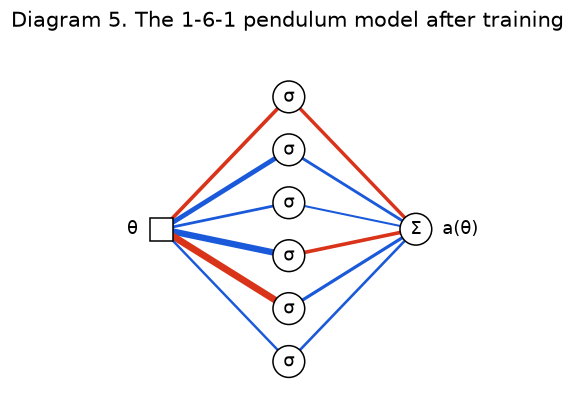

In [38]:
# c.22b
# the trained force-law network: angle in, acceleration out
diagram([([1, 6, 1], histP[-1][2], ["θ"], ["a(θ)"], "Σ", "")],
        "Diagram 5. The 1-6-1 pendulum model after training")

*Table 12b. The trained pendulum model as matrix products at θ = 1: a 6 × 1 column of weights, then a 1 × 6 row. The result is within 0.02 of -sin 1.*

In [39]:
# c.22c
# the trained pendulum model in matrices, at θ = 1: W1 is 6×1,
# W2 is 1×6
(W1p, b1p), (W2p, b2p) = histP[-1][2]
z1p = W1p @ [0.5] + b1p; h1p = sigma(z1p)
z2p = W2p @ h1p + b2p
mtable([
    ("hidden layer:  z = W (θ/2) + b", row(mat(W1p), " ", col([0.5]), " + ", col(b1p), " = ", col(z1p))),
    ("h = σ(z)", row("σ", col(z1p), " = ", col(h1p))),
    ("output layer:  a = W h + b", row(mat(W2p), " ", col(h1p), " + ", col(b2p), " = ", col(z2p))),
    ("compare with the true force law", f"a(1) = {z2p[0]:.4g},   -sin 1 = {-np.sin(1.):.4g}")],
    "Table 12b. The pendulum model as matrix products")

step and matrix form
2.1
-2.91
-1.45
-4.07
4.43
-1.22
0.5
-2.7
-4.04
1.7


*Figure 9. Pick a training snapshot and press play on time (shown for the trained model at t = 0). Top left: the learned pendulum (orange) beside the true one (gray). Top right: the learned force law against the measurements and -sin θ. Bottom: the angle over 40 s; early models fall out of step, the trained one stays in step with the true pendulum.*

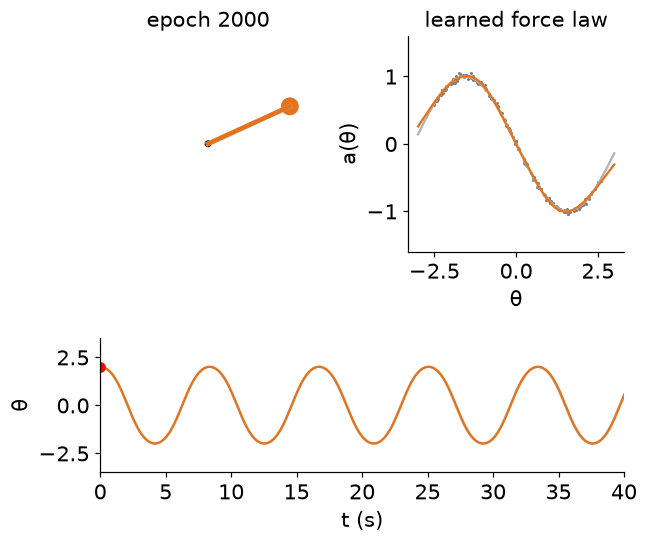

In [40]:
# c.23
# the learned pendulum (orange) beside the real one (gray): pick a
# training snapshot, then press play on time
pickP = list(range(1, 22)) + [26, 31, 41, 61, 101, 151, len(histP)]
trajL = [nestList(leap(accel(histP[k - 1][2])), p0, 800) for k in pickP]
lawL = [np.array([accel(histP[k - 1][2])(t) for t in np.linspace(-3, 3, 241)]) for k in pickP]
def bob(ax, th, c):
    ax.plot([0, np.sin(th)], [0, -np.cos(th)], color=c, lw=3)
    ax.add_patch(plt.Circle((np.sin(th), -np.cos(th)), 0.09, color=c))
def pendView(fig, j, n):
    fig.clf()
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.55])
    a1, a2, a3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
    bob(a1, truthP[n - 1, 0], (0.75,) * 3); bob(a1, trajL[j - 1][n - 1, 0], orange)
    a1.add_patch(plt.Circle((0, 0), 0.03, color="black"))
    a1.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal", title=f"epoch {histP[pickP[j - 1] - 1][0]}")
    a1.axis("off")
    tt = np.linspace(-3, 3, 241)
    a2.plot(thD, aD, ".", color="gray", ms=2)
    a2.plot(tt, -np.sin(tt), color=(0.7,) * 3); a2.plot(tt, lawL[j - 1], color=orange)
    a2.set(ylim=(-1.6, 1.6), xlabel="θ", ylabel="a(θ)", title="learned force law", box_aspect=1)
    tg = np.linspace(0, 40, 801)
    a3.plot(tg, truthP[:, 0], color=(0.75,) * 3); a3.plot(tg, trajL[j - 1][:, 0], color=orange)
    a3.plot(h * (n - 1), trajL[j - 1][n - 1, 0], "o", color="red", ms=6)
    a3.set(xlim=(0, 40), ylim=(-3.5, 3.5), xlabel="t (s)", ylabel="θ")
    fig.tight_layout()
jSnapP = slider("training snapshot", 1, len(pickP))
nTimeP, boxTimeP = player("time", 1, 801, fps=20)
manipulate(pendView, (wFull, 0.85 * wFull), {"j": jSnapP, "n": nTimeP}, {"j": len(pickP), "n": 1},
           [jSnapP, boxTimeP])

▶ **Video:** [Pendulum-learning.mp4](videos/Pendulum-learning.mp4), learned pendulums at four stages of training.

▶ **Unity 6 version in 3D:** the cart-pole and the learned pendulum with these trained networks, [in 4K on YouTube](https://youtu.be/lIUtEO9m79M); project: [neural-networks-unity](https://github.com/lossofgenerality/neural-networks-unity).

## 10. The same with PyTorch

A neural network framework builds the same networks from layers. The Wolfram notebook uses Wolfram Language's own, NetChain and NetTrain; here it is PyTorch. nn.Linear(n, m) is W x + b with m outputs (Wolfram: LinearLayer[m]), nn.Sigmoid is σ, nn.Sequential chains the layers (NetChain), and the training loop does backpropagation, by PyTorch's automatic differentiation, and gradient descent with Adam, Eq. (19), in batches of 64 samples, as NetTrain does by default.

*Table 13. PyTorch against our code on XOR and on the cart-pole. The numbers differ slightly because the starting weights and the optimizer differ, but both controllers balance the stick.*

In [41]:
# c.24
# the same networks with PyTorch: nn.Linear is W x + b (Wolfram:
# LinearLayer), nn.Sigmoid is σ, nn.Sequential chains them (NetChain),
# and the loop below with Adam plays the part of NetTrain
import torch
from torch import nn
torch.set_default_dtype(torch.float32)
torch.set_num_threads(1)    # small networks: one thread is fastest
def netTrain(chain, X, Y, rounds, lr=1e-3, batch=64, seed=1):
    # Adam on the mean squared error, in batches of 64 samples, the
    # data shuffled every round, as NetTrain does by default
    g = torch.Generator().manual_seed(seed)
    X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
    opt = torch.optim.Adam(chain.parameters(), lr=lr)
    for _ in range(rounds):
        for idx in torch.randperm(len(X), generator=g).split(batch):
            opt.zero_grad()
            nn.functional.mse_loss(chain(X[idx]), Y[idx]).backward()
            opt.step()
    return chain
run = lambda chain, X: chain(torch.tensor(X, dtype=torch.float32)).detach().numpy()
# XOR: 2 inputs, 3 σ neurons, 1 σ output, as in Table 7
torch.manual_seed(1)
xorChain = nn.Sequential(nn.Linear(2, 3), nn.Sigmoid(), nn.Linear(3, 1), nn.Sigmoid())
xorTrained = netTrain(xorChain, xorX, xorT, 2000, lr=0.05)
# cart-pole: 4 inputs, 8 σ neurons, linear output
torch.manual_seed(1)
cpChain = nn.Sequential(nn.Linear(4, 8), nn.Sigmoid(), nn.Linear(8, 1))
cpTrained = netTrain(cpChain, cpX, cpY, 300)
# the trained chain as a controller, same scaling as ctrl
ctrlChain = lambda s: float(np.clip(umax * run(cpTrained, (s / scale)[None])[0, 0], -umax, umax))
table([["network", "result"],
       ["XOR, PyTorch", nform(run(xorTrained, xorX).ravel(), 3)],
       ["XOR, our backprop (Table 7)", nform(forward(histX[-1][2], xorX, sigma)[-1].ravel(), 3)],
       ["cart-pole, PyTorch controller", fate(sim(ctrlChain, s0, 300))],
       ["cart-pole, our controller (Table 11)", fate(sim(ctrl(netC), s0, 300))]], "Table 13")

network,result
"XOR, PyTorch","(0.00724, 0.998, 0.99, 0.00773)"
"XOR, our backprop (Table 7)","(0.0218, 0.977, 0.978, 0.0259)"
"cart-pole, PyTorch controller",balances
"cart-pole, our controller (Table 11)",balances


To see that nothing more is hidden inside the framework, take the trained weights out of the cart-pole network in PyTorch and run them through forward of cell c.9.

*Table 14. PyTorch and our forward pass, with the same weights, agree to single precision (PyTorch computes in float32).*

In [42]:
# c.25
# PyTorch does exactly our algebra: take the weights out of the
# trained chain and run them through forward of c.9
netFromChain = [(cpTrained[i].weight.detach().numpy().astype(float),
                 cpTrained[i].bias.detach().numpy().astype(float)) for i in (0, 2)]
# the force for all 3000 states, by PyTorch and by us
uChain = run(cpTrained, cpX).ravel()
uOurs = forward(netFromChain, cpX, identity)[-1].ravel()
table([["quantity", "value"],
       ["shapes of W, b in the chain", ", ".join(str(a.shape) for l in netFromChain for a in l)],
       ["max |PyTorch output - forward of c.9|", sci(np.abs(uChain - uOurs).max())]], "Table 14")

quantity,value
"shapes of W, b in the chain","(8, 4), (8,), (1, 8), (1,)"
max |PyTorch output - forward of c.9|,2.7 × 10-7


## Appendix A. The formulas in one place

- One neuron: z = w·x + b, a = σ(z), Eqs. (1)–(2); σ′ = σ(1 - σ), Eq. (3).
- A layer: z = W x + b with W of size m × n (outputs × inputs), Eq. (4); for M samples as rows, Z = X ${W}^{T}$ + b, Eq. (5).
- A network: ${a}^{0}$ = x; ${z}^{l}$ is ${W}^{l}$ times the activations of the previous layer, plus ${b}^{l}$; ${a}^{l}$ = σ(${z}^{l}$), Eq. (6).
- Losses: squared error, Eq. (8); softmax and cross-entropy, Eqs. (9)–(10).
- Backpropagation: ${\delta}^{L}$ from Eq. (11), ${\delta}^{l}$ from Eq. (12), gradients from Eq. (13); the gradient of ${W}^{l}$ has the shape of ${W}^{l}$.
- Training: ${W}^{l}$ ← ${W}^{l}$ - η ∂L/∂${W}^{l}$, Eq. (14); one epoch is one pass over the data; Adam, Eq. (19), adapts the step for each weight.
- Learning dynamics: a network can learn what to do (a controller, Section 8) or how a system moves (a model, Section 9); a model of the force that depends on the position alone conserves energy, Theorem 4.
- Shapes in the code: X is M × n, every ${A}^{l}$ is M × (neurons of layer l), every δ is M × (neurons of its layer), and ∂L/∂${W}^{l}$ is ${\delta}^{T}$ A of the previous layer.

## Appendix B. Saving the animations as videos

Every interactive cell of this notebook draws its frames with one function of the control values: stepView, xorFrame, cpView, pushFrame and pendView, in cells c.0.4, c.14, c.20, c.21 and c.23. Cell c.26 draws a list of frames with such a function and writes them to an MP4 file with Matplotlib's FFMpegWriter, into the folder of the notebook: the 13 steps of Figure 0.1, the XOR training of Figure 5, the push test of Figure 8, the cart-pole at four stages of training (Figure 7) and the trained pendulum model (Figure 9). It needs the whole notebook to have been run first and the program ffmpeg to be installed (on macOS: brew install ffmpeg), and drawing several hundred frames takes a few minutes. The videos made by the Wolfram notebook are already in [`videos/`](videos), so every value of doExport starts as False and the cell makes nothing; set a value to True to make that video.

The same idea works for any interactive figure: write it as a function of the control values, as in c.20 and c.23, then draw that function over the values to be shown.

*Table 15. The exported videos and their sizes.*

In [43]:
# c.26
# save the animations as MP4 videos in the notebook's folder. Run the
# notebook first (c.0 to c.25). This draws every frame, so it takes a
# few minutes and needs ffmpeg; set a value of doExport to True to make
# that video (all are off, so that Run All stays quick)
from matplotlib.animation import FFMpegWriter
doExport = {"steps": False, "xor": False, "push": False, "balance": False, "pendulum": False}
def video(name, view, figsize, frames, fps):
    fig = plt.figure(figsize=figsize)
    writer = FFMpegWriter(fps=fps)
    with writer.saving(fig, name, dpi=110):
        for kw in frames:
            view(fig, **kw)
            writer.grab_frame()
    plt.close(fig)
    return pathlib.Path(name)
if any(doExport.values()) and shutil.which("ffmpeg") is None:
    print("ffmpeg was not found: install it (macOS: brew install ffmpeg) to export videos")
    doExport = dict.fromkeys(doExport, False)
files = []
if doExport["steps"]:
    files.append(video("Tiny-network-13-steps.mp4", stepView, (wFull * 1.3, wFull * 0.66),
                       [{"k": k} for k in range(1, len(allSteps) + 1)], 1))
if doExport["xor"]:
    files.append(video("XOR-training.mp4", xorFrame, (wHalf * 1.3, wHalf * 1.3),
                       [{"f": f} for f in range(1, len(xorPick) + 1)], 8))
if doExport["push"]:
    files.append(video("CartPole-push-test.mp4", pushFrame, (wFull, 0.42 * wFull),
                       [{"f": f} for f in range(1, len(pushN) + 1)], 25))
# Figure 7 at four training snapshots, 6 s each
if doExport["balance"]:
    files.append(video("CartPole-learning.mp4", cpView, (wFull, 0.62 * wFull),
                       [{"j": j, "n": n} for j in (1, 3, 5, len(pick)) for n in range(1, 302, 3)], 17))
# Figure 9 for the trained model: 40 time units
if doExport["pendulum"]:
    files.append(video("Pendulum-learned.mp4", pendView, (wFull, 0.85 * wFull),
                       [{"j": len(pickP), "n": n} for n in range(1, 802, 4)], 20))
table([["video", "size"]] + [[f.name, f"{round(f.stat().st_size / 1024)} kB"] for f in files] +
      ([] if files else [["(no video made: all doExport values are False)", ""]]),
      "Table 15. The exported videos")

video,size
(no video made: all doExport values are False),


## References

- [1] D. O Shayda, N. Hoshino, S Shape Functions Theory, Computational Classnotes (2026).
- [2] M. Minsky, S. Papert, Perceptrons, MIT Press (1969): the XOR limitation of a single layer.
- [3] G. Cybenko, Approximation by superpositions of a sigmoidal function, Math. Control Signals Systems 2 (1989) 303–314. doi:10.1007/BF02551274
- [4] D. E. Rumelhart, G. E. Hinton, R. J. Williams, Learning representations by back-propagating errors, Nature 323 (1986) 533–536. doi:10.1038/323533a0
- [5] M. A. Nielsen, Neural Networks and Deep Learning, Determination Press (2015), neuralnetworksanddeeplearning.com
- [6] I. Goodfellow, Y. Bengio, A. Courville, Deep Learning, MIT Press (2016), deeplearningbook.org
- [7] A. G. Barto, R. S. Sutton, C. W. Anderson, Neuronlike adaptive elements that can solve difficult learning control problems, IEEE Trans. Systems, Man, and Cybernetics 13 (1983) 834–846: the cart-pole equations and parameters used here.
- [8] B. Widrow, F. W. Smith, Pattern-recognizing control systems, in Computer and Information Sciences (COINS) Symposium Proceedings, Spartan Books (1964) 288–317: a network taught to balance a broom by imitation.
- [9] E. Hairer, C. Lubich, G. Wanner, Geometric numerical integration illustrated by the Störmer–Verlet method, Acta Numerica 12 (2003) 399–450: why leapfrog keeps the energy.
- [10] D. P. Kingma, J. Ba, Adam: A method for stochastic optimization, ICLR 2015, arXiv:1412.6980.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>